---
title: "Axial dispersion and kLa in tall bubble columns (Deckwer, Burckhart and Zoll, 1974)"
description: "The liquid axial dispersion model Deckwer, Burckhart and Zoll fitted to oxygen profiles in two tall bubble columns, its three simplifications tested at the paper's own operating points, and the coupled liquid-dispersion and gas plug-flow model the paper set aside, solved with pymrm."
categories: [sec:F, struct:S7, struct:S4, tier:T1, data:tier4, phase:gas-liquid]
date: 2026-11-23
---

# Axial dispersion and mass transfer in tall bubble columns

**Catalog ID:** `F2.1` · **Structures:** `S7` (gas-liquid coupling), `S4` (1-D convection,
dispersion and exchange) · **Tier:** T1

Deckwer, Burckhart and Zoll (1974) measured oxygen profiles along two tall bubble
columns and read the volumetric mass-transfer coefficient $k_La$ from them by fitting a
liquid-only axial dispersion model, with the gas composition prescribed rather than
solved. They defended that evaluation with three statements: the dispersion coefficient
hardly matters, a plug-flow (NTU) evaluation is at most 20 per cent low, and a varying
gas composition matters by at most 20 per cent. This page tests each statement at the
paper's own operating points, against the scatter of the paper's own $k_La$
correlation, and solves with pymrm the coupled liquid-dispersion and gas plug-flow
model that the paper named and set aside.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.10"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F2.1-deckwer-bubble-column-dispersion"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (CoupledColumn, adm_printed_A6_A11, adm_profile, capacity_ratio,
                   coupled_bvp, cstar_coefficients, cstr_outlet, danckwerts_outlet_ratio,
                   dispersion_eq1, dy_from_outlet, fit_stanton, head_atm, kla_eq8,
                   liquid_velocity, peclet, plug_profile, roots_A7, stanton,
                   st_two_point_cstr, st_two_point_ntu, y_over_yref)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])

## Background

In a tall bubble column the liquid is neither plug flow nor well mixed: rising bubbles
drag liquid up in the core and let it fall at the wall, and the net effect along the
axis is described by an axial dispersion coefficient $D$. Deckwer, Burckhart and Zoll
measured $D$ (their eq. 1) and the gas holdup in two columns, BC I (20 cm diameter,
723 cm long, cross of nozzles) and BC II (15 cm, 440 cm, sintered plate), and then
measured the dissolved-oxygen profile along the height in absorption from air (BC I)
and desorption into nitrogen (BC II). They obtained $k_La$ by fitting the liquid
dispersion model to each profile, and summarised the fits as $k_La = b_0 u_G^{b_1}$
(their Table 1).

The paper does not solve a two-phase model. The gas composition enters only as a
prescribed equilibrium concentration $c^*$: constant mole fraction (eq. 6) or a mole
fraction linear in height (eq. 7). The coupled gas balance is named on p. 2183 and set
aside because it is nonlinear. The evaluation is defended by three statements, quoted
from the paper:

- **S1** (p. 2182): fitting $D$ instead of using the measured one changes it "up to
  100 per cent", while the Stanton numbers "do not differ more than 3 per cent", for
  "D > 100 cm²/sec".
- **S2** (p. 2184, Fig. 11): the plug-flow NTU evaluation gives $k_La$ lower, by an
  amount that "does not exceed more than 20 per cent"; a stirred-tank evaluation gives
  values that are too high (p. 2180).
- **S3** (p. 2183): the gas mole fraction changes by not more than 0.04, and with
  eq. 7 the $k_La$ is "increased up to 20 per cent" at low gas and high liquid flow.

**The question.** At the paper's own operating points, which simplification of the
evaluation moves the fitted $k_La$ by more than the scatter of the paper's own
correlation (Table 1: relative mean deviation 14.9 % for BC I water, 14.6 % for BC II
water): the liquid mixing input ($D$ by a factor 2, plug flow, stirred tank) or the gas
phase (constant $y$, eq. 7, against the coupled model the paper did not solve)?

**Not covered here.** Gas holdup (Figs. 1 to 3 are inputs only), the mixing-time
method (Fig. 4), the salt and molasses effects on $k_L$ (Figs. 12, 13), axial variation
of $k_La$ and of the local gas velocity (both held constant, as the paper does), and
gas-phase dispersion (no gas dispersion coefficient is printed). The Danckwerts
conditions and the closed-vessel solution belong to [`A2.1`](../A2.1-danckwerts-boundary-conditions/);
$k_La$ correlations to [`F1.1`](../F1.1-akita-yoshida-bubble-column/).

## The published model

Units as in the paper: lengths in cm, velocities in cm/s, $D$ in cm²/s, $k_La$ in
1/s, $c$ in mg/l, $p$ in atm, $V_L$ in m³/h. In $x = z/L$:

| | equation | source |
|---|---|---|
| E1 | $D = 2.7\, d^{1.4} u_G^{0.3}$ | eq. 1 |
| E2 | $k_La = b_0 u_G^{b_1}$ (Table 1) | eq. 8 |
| E3 | $u_{L0} = V_L / (\pi d^2/4)$ | page |
| E4, E5 | $\mathrm{Pe} = u_{L0} L / (D (1-\varepsilon_G))$, $\mathrm{St} = k_La L / u_{L0}$ | eqs. 4, 5 |
| E6 | $c^* = y\, p(x)/H$, $p = p_t + \rho g \varepsilon_L L (1-x)$ | eqs. 6, A2, A3 |
| E7 | $\frac{1}{\mathrm{Pe}} c'' - c' + \mathrm{St}(c^* - c) = 0$, $c(0) - \frac{1}{\mathrm{Pe}} c'(0) = c_0$, $c'(1) = 0$ | eqs. 3, A4, A5 |
| E8 | eq. 7: $y = y_0 + \Delta y_t\, x$, so $c^*$ is quadratic in $x$ | eqs. 7, A12 to A20 |

The closed forms of E7 (linear $c^*$, eqs. A6 to A11) and of E8 (quadratic $c^*$, eqs.
A16 to A20) are in `model.py`, `adm_profile`. Three misprints were found on the page
images and are corrected; each is a row of the break table below and its effect is
measured in the Validation section:

- **M1.** A4 prints $c(0) = c_0 - \frac{1}{\mathrm{Pe}} c'(0)$. The printed solution A8 to
  A11 solves the Danckwerts inlet $c(0) - \frac{1}{\mathrm{Pe}} c'(0) = c_0$ (substitute it:
  the inlet row becomes A10 because $\mathrm{Pe} - r_1 = r_2$).
- **M2.** A19 prints the prefactor of $B_3$ as $2\gamma/\mathrm{Pe}$; substitution gives
  $2\gamma/\mathrm{St}$.
- **M3.** A13 prints $b' = \rho g \varepsilon_L L / H$ without the minus sign of A3; with it,
  $c^*$ would rise with height.

Two further notes: p. 2187 says "Eq. (7) is introduced in Eq. (5)" for Eq. (6), and
p. 2177 attributes the nozzle cross to BC II where it is BC I's sparger. Neither enters
a number.

**The coupled model (the page's, not the paper's).** The gas is in plug flow, its
oxygen flux following the transfer with the inert gas conserved:
$\psi' = -\Lambda\,\mathrm{St}\,(\theta^* - \theta)$, $\theta^* = (y/y_{\mathrm{ref}}) P(x)$,
$y/y_{\mathrm{ref}} = \psi / ((1-y_0) + y_{\mathrm{ref}}\psi)$, with $\theta = c/c_{\mathrm{ref}}$,
$\psi = F/(y_{\mathrm{ref}} n_{G0})$, $F = G y/(1-y)$ and the capacity ratio
$\Lambda = u_{L0} c_{\mathrm{ref}} / (M y_{\mathrm{ref}} n_{G0})$. The liquid obeys E7 with
this $\theta^*$. The overall balance $\theta(1) - \theta_0 = (\psi_0 - \psi(1))/\Lambda$
gives the $\Delta y_t$ that eq. 7 needs from the measured outlet ("determined by an
overall oxygen balance", p. 2183).

| symbol | code |
|---|---|
| $\mathrm{Pe}, \mathrm{St}, \Lambda$ | `Pe`, `St`, `Lam` |
| $\theta, \psi$ | columns 0 and 1 of `CoupledColumn.c` |
| $\theta^* = \alpha + \beta x + \gamma x^2$ | `cstar_coefficients` |
| $h = \rho g \varepsilon_L L / p_t$ | `head_ratio`, `h` |

## Parameters and assumptions

Every printed constant is loaded from `deckwer-1974-printed-numbers.csv` and Table 1
from `deckwer-1974-table1.csv`; nothing printed is retyped. The inputs the paper does
not print are named here, each with its source, and nothing is fitted to make S1 to S3
hold:

- $L$ is the column length (723 cm and 440 cm): the paper gives no separate dispersion
  height. $u_G$ in eqs. 1 and 8 is $u_{G0}$ at the column entry (the figures plot
  $u_{G0}$).
- $n_{G0}$ in $\Lambda$ is the molar gas flow at the column entry, at the pressure
  $p(0) = p_t (1 + h)$ with $h$ the hydrostatic head over $p_t$: $u_{G0}$ is the gas velocity
  at the entry (the figures plot it), so the moles follow from the entry pressure. R4
  prints the effect of taking $p_t$ instead (`gas_p="top"`).
- $p_t = 1$ atm, $\rho = 0.999$ g/cm³, $g = 981$ cm/s², $R = 82.0574$ cm³ atm/(mol K),
  $M = 32$ g/mol, $T = 16$ °C (printed).
- $c^*_{\mathrm{sat}} = 9.86$ mg/l for water under air at 16 °C and 1 atm (Benson and
  Krause 1984), which sets $H = 0.21\,p_t / c^*_{\mathrm{sat}}$. $H$ is not printed; its
  effect on R4 is measured with $c^*_{\mathrm{sat}}$ 5 % up and down.
- **Assumption (feed of BC I).** The feed $c_0 = 0.6$ mg/l for every BC I absorption point:
  Fig. 10 marks two feeds on its ordinate (about 0.66 and 1.05 mg/l, open circles) that
  cannot be assigned to one of the two BC I curves by marker shape. R2 depends on it only
  weakly and R4 through $\theta_0$; R2 prints the largest St changes and the counts with the
  other feed mark (1.05 mg/l).
- **Assumption (feed of BC II water).** $c_0 = 5.42$ mg/l, read at the square mark on
  Fig. 10's ordinate (the only mark with that shape).
- The 0.7 N Na₂SO₄ points use the water row of their column: Table 1 has no such row,
  and p. 2184 says those data are "about the same as those for water". They are
  flagged as proxies and counted separately.
- $k_La$ and $\varepsilon_G$ are constant along the column, as in the paper. The gas
  enters BC I as air ($y_0 = 0.21$) and BC II as nitrogen ($y_0 = 0$).

In [3]:
PN = load_data("deckwer-1974-printed-numbers.csv", page=PAGE, dtype=str).set_index("name")["printed"]
T1 = load_data("deckwer-1974-table1.csv", page=PAGE)
OPS = load_data("deckwer-1974-operating-points.csv", page=PAGE).set_index("id")
HU = load_data("deckwer-1974-holdup-reads.csv", page=PAGE)
PORTS = load_data("deckwer-1974-fig10-ports.csv", page=PAGE)
FEEDS = load_data("deckwer-1974-fig10-feeds.csv", page=PAGE)
F11 = load_data("deckwer-1974-fig11.csv", page=PAGE)

# One dictionary of constants that every study takes, so a break row is one call (rule 34).
K0 = dict(
    D_coef=float(PN["D_coef"]), D_exp_d=float(PN["D_exp_d"]), D_exp_uG=float(PN["D_exp_uG"]),
    p_t=1.0,            # atm, total pressure at the top (external)
    rho=0.999,          # g/cm3, water at 16 C (external)
    g=981.0,            # cm/s2
    R=82.0574,          # cm3 atm/(mol K)
    M=32.0,             # g/mol, O2
    T_K=273.15 + float(PN["T_C"]),
    csat=9.86,          # mg/l, O2 under air at 16 C, 1 atm (Benson and Krause 1984, external)
    y_air=float(PN["y0_air"]),
    y_ref=0.21,         # reference mole fraction of the scaling (also for desorption)
    c0_abs=0.6,         # mg/l, feed of every BC I absorption point (assumption, see above)
)
DIMS = {"BC I": (float(PN["d_BCI_cm"]), float(PN["L_BCI_cm"])),
        "BC II": (float(PN["d_BCII_cm"]), float(PN["L_BCII_cm"]))}
OTHER = {"BC I": "BC II", "BC II": "BC I"}
FEED_MARK = {"F10-BCII-H2O-2.5": "square", "F10-BCII-Na2SO4-2.0": "filled circle"}
SCATTER = {c: float(T1[(T1.column == c) & (T1.liquid == "water")].rel_mean_dev_pct.iloc[0]) / 100
           for c in DIMS}
print("Table 1 scatter (relative mean deviation, water):",
      {c: f"{100 * s:.1f} %" for c, s in SCATTER.items()})

Table 1 scatter (relative mean deviation, water): {'BC I': '14.9 %', 'BC II': '14.6 %'}


## The data

Every dataset below was read from the page images at 300 dpi (the text layer of the
scan substitutes digits) and has a `data/*.meta.yaml` provenance sidecar with the
reading method and its error. No dataset is borrowed from another page.

- `deckwer-1974-printed-numbers.csv`: eq. 1, column dimensions, temperature, the
  Fig. 5 liquid velocity, the gas entry mole fraction and the numbers of S1 to S3, as
  printed (read as strings).
- `deckwer-1974-table1.csv`: Table 1, every row.
- `deckwer-1974-operating-points.csv`: the ten profiles of Figs. 9 and 10 with their
  legends, the Table 1 row each uses, and the proxy flag.
- `deckwer-1974-holdup-reads.csv`: $\varepsilon_G$ at each operating point from Figs. 1
  to 3, and the drawn tap-water lines of Fig. 1 for the maps ($\pm 0.01$).
- `deckwer-1974-fig10-ports.csv`: the measuring-port positions of each column (fit
  design D1), read from the Fig. 10 markers ($\pm 0.003$).
- `deckwer-1974-fig10-feeds.csv`: the feed marks on Fig. 10's ordinate, with whether the
  marker shape assigns each to one curve.
- `deckwer-1974-fig11.csv`: Fig. 11's BC II correlation line and its dashed NTU line,
  read on six vertical lines (about 2 % per read).
- `check_values.csv`: values of the page's functions at one test condition, computed
  by a second route (a separate script), asserted below before any claim.

The measured profiles of Figs. 9 and 10 are not digitised: every result here is a
self-consistency test of the evaluation at the paper's operating points, not a new
measurement.

In [4]:
for name in ("deckwer-1974-table1.csv", "deckwer-1974-holdup-reads.csv",
             "deckwer-1974-fig10-ports.csv", "deckwer-1974-fig11.csv"):
    print(cite_data(load_meta(name, page=PAGE)))
print(OPS[["figure", "column", "liquid", "mode", "VL_m3h", "uG0_cm_s", "table1_row", "proxy"]])

Deckwer, W.-D.; Burckhart, R.; Zoll, G. (1974) — Chemical Engineering Science 29(11) 2177-2188 — doi:10.1016/0009-2509(74)80025-4 — page-image transcription
Deckwer, W.-D.; Burckhart, R.; Zoll, G. (1974) — Chemical Engineering Science 29(11) 2177-2188 — doi:10.1016/0009-2509(74)80025-4 — digitised from Figs. 1 (p. 2178), 2 (p. 2178) and 3 (p. 2179)
Deckwer, W.-D.; Burckhart, R.; Zoll, G. (1974) — Chemical Engineering Science 29(11) 2177-2188 — doi:10.1016/0009-2509(74)80025-4 — digitised from Fig. 10, p. 2183
Deckwer, W.-D.; Burckhart, R.; Zoll, G. (1974) — Chemical Engineering Science 29(11) 2177-2188 — doi:10.1016/0009-2509(74)80025-4 — digitised from Fig. 11, p. 2184
                      figure column              liquid        mode  VL_m3h  \
id                                                                            
F9-BCI-Na2SO4         Fig. 9   BC I        Na2SO4 0.7 N  absorption     0.8   
F9-BCI-H2O            Fig. 9   BC I               water  absorption     0.8   
F9-BC

In [5]:
def table1(column, row):
    """b0, b1 of the Table 1 row ``row`` of ``column``."""
    r = T1[(T1.column == column) & (T1.liquid == row)]
    return float(r.b0.iloc[0]), float(r.b1.iloc[0])


def eps_line(column, uG):
    """Gas holdup on the drawn tap-water line of Fig. 1 (piecewise linear through the reads)."""
    ln = HU[(HU.kind == "line") & (HU.column == column)]
    return float(np.interp(uG, ln.uG0_cm_s, ln.eps_G))  # interpolation of digitised data


def eps_point(pid):
    """Gas holdup read at one operating point (Figs. 1 to 3)."""
    return float(HU[(HU.kind == "point") & (HU.id == pid)].eps_G.iloc[0])


def point(pid, K=K0, VL=None, uG=None, eps=None, swap_table=False, drop_epsL=False,
          swap_dims=False, gas_p="entry"):
    """Dimensionless groups of one operating point (eqs. 1, 4 to 6, 8 and the gas capacity).

    The defects of the break table enter as arguments: ``swap_table`` uses the other
    column's Table 1 row, ``drop_epsL`` drops (1 - eps_G) from Pe, ``swap_dims`` takes the
    other column's diameter and length, ``gas_p="top"`` takes the gas flow n_G0 at the top
    pressure p_t instead of the entry pressure p_t (1 + h).
    """
    op = OPS.loc[pid]
    col = op.column
    d, L = DIMS[OTHER[col] if swap_dims else col]
    VL = float(op.VL_m3h) if VL is None else VL
    uG = float(op.uG0_cm_s) if uG is None else uG
    eps = eps_point(pid) if eps is None else eps
    tcol = col
    if swap_table and ((T1.column == OTHER[col]) & (T1.liquid == op.table1_row)).any():
        tcol = OTHER[col]
    b0, b1 = table1(tcol, op.table1_row)
    uL = liquid_velocity(VL, d)
    D = dispersion_eq1(d, uG, K["D_coef"], K["D_exp_d"], K["D_exp_uG"])
    kla = kla_eq8(uG, b0, b1)
    Pe = peclet(uL, L, D, 0.0 if drop_epsL else eps)
    St = stanton(kla, L, uL)
    h = head_atm(eps, L, K["rho"], K["g"]) / K["p_t"]
    H = K["y_air"] * K["p_t"] / K["csat"]          # atm l/mg, from the saturation value
    c_ref = K["y_ref"] * K["p_t"] / H              # mg/l
    Lam = capacity_ratio(uL, c_ref, K["M"], K["y_ref"], uG,
                         K["p_t"] * (1 + h) if gas_p == "entry" else K["p_t"], K["R"], K["T_K"])
    absorption = op["mode"] == "absorption"
    y0 = K["y_air"] if absorption else 0.0
    if absorption:
        c0 = K["c0_abs"]
    elif pid in FEED_MARK:
        c0 = float(FEEDS[FEEDS.marker == FEED_MARK[pid]].c0_mgl.iloc[0])
    else:
        c0 = None   # c* = 0: relative results do not depend on the feed
    return dict(id=pid, column=col, uL=uL, D=D, eps=eps, kla=kla, Pe=Pe, St=St, h=h, H=H,
                c_ref=c_ref, Lam=Lam, y0=y0, psi0=y0 / K["y_ref"], c0=c0,
                theta0=(c0 / c_ref) if c0 is not None else 1.0, uG=uG, VL=VL, L=L, d=d)

### The functions against the check values

`check_values.csv` holds 45 values at one test condition T (Fig. 10, BC I, tap water,
$V_L$ 3.0 m³/h, $u_{G0}$ 0.65 cm/s, $\varepsilon_G$ fixed at 0.023, $c_0$ 0.6 mg/l, fit design
D2), computed by a separate script: closed forms, the `solve_bvp` route of the coupled
model, and the fits as roots of the analytic gradient. The page's functions reproduce
them here, before any claim; the finite-volume rows (rtol 1e-7) are compared after a
Richardson extrapolation with the first- and second-order terms on $n$ = 640, 1280,
2560, since the inlet face value $c(0)$ carries a strong second-order term that a
first-order extrapolation leaves in.

In [6]:
XK = np.arange(1, 21) / 20          # fit design D2: x = k/20 (falls on faces of every grid used)
NS_R = (640, 1280, 2560)            # the three grids of every extrapolated finite-volume value
EPS_T = 0.023                       # holdup fixed by the check script at T


def richardson(qs, two_term=True):
    """Extrapolate values on grids n, 2n, 4n: orders 1 and 2 removed, or order 1 only."""
    q1, q2, q4 = (np.asarray(q, dtype=float) for q in qs[-3:])
    return (8 * q4 - 6 * q2 + q1) / 3 if two_term else 2 * q4 - q2


def coupled_values(pt, n, inlet_sign=1.0, gas_outlet="outflow", outlet_read="face",
                   bprime_sign=-1.0, tol=1e-11, lin_solver_kwargs=None, Lam=None, y0=None):
    """One finite-volume solve: [theta(0), theta(1), psi(1), theta(XK[:-1]), psi(0.5)]."""
    y0 = pt["y0"] if y0 is None else y0
    m = CoupledColumn(pt["Pe"], pt["St"], pt["Lam"] if Lam is None else Lam, pt["theta0"],
                      y0 / K0["y_ref"], y0, K0["y_ref"], pt["h"], n=n, inlet_sign=inlet_sign,
                      gas_outlet=gas_outlet, outlet_read=outlet_read, bprime_sign=bprime_sign)
    m.solve(tol=tol, lin_solver_kwargs=lin_solver_kwargs)
    a, b, c = m.boundary()
    th, _ = m.at(XK[:-1])
    _, ps5 = m.at(0.5)
    return np.r_[a, b, c, th, ps5]


def coupled_extrapolated(pt, two_term=True, ns=NS_R, **kw):
    """Richardson-extrapolated coupled values on the grids ``ns``."""
    return richardson([coupled_values(pt, n, **kw) for n in ns], two_term)


def unpack(q, pt, y_ref=K0["y_ref"]):
    """Named quantities of a coupled value vector."""
    th0f, th1f, psi1 = q[0], q[1], q[2]
    data = np.r_[q[3:3 + len(XK) - 1], th1f]       # theta at XK, the outlet on its face
    dyt = y_ref * y_over_yref(psi1, pt["y0"], y_ref) - pt["y0"]
    y_half = y_ref * y_over_yref(q[-1], pt["y0"], y_ref)
    return dict(th0f=th0f, th1f=th1f, psi1=psi1, data=data, dyt=dyt,
                y_half_dev=y_half - (pt["y0"] + 0.5 * dyt))


PT_T = point("F10-BCI-H2O-3.0", eps=EPS_T)
ref = PT_T["c_ref"]
al_T, be_T, ga_T = cstar_coefficients(K0["y_air"], 0.0, K0["y_ref"], PT_T["h"])
r1_T, r2_T = roots_A7(PT_T["Pe"], PT_T["St"])
CV = dict(uL0_cm_s=PT_T["uL"], uL0_VL0p8_cm_s=liquid_velocity(0.8, PT_T["d"]),
          D_eq1_cm2_s=PT_T["D"], kLa_table1_1_s=PT_T["kla"], Pe_eq4=PT_T["Pe"],
          St_eq5=PT_T["St"], hydrostatic_head_atm=PT_T["h"] * K0["p_t"],
          H_atm_l_mg=PT_T["H"], Lambda_capacity_ratio=PT_T["Lam"], r1_A7=r1_T, r2_A7=r2_T)
_args = (PT_T["Pe"], PT_T["St"])
_lin = adm_profile([0, 0.5, 1], *_args, al_T, be_T, ga_T, PT_T["theta0"]) * ref
CV.update(linear_c0face_mgl=_lin[0], linear_c_half_mgl=_lin[1], linear_c_out_mgl=_lin[2])
CV["printed_A6_A11_over_corrected_c_out"] = (
    adm_printed_A6_A11(1.0, *_args, al_T, be_T, PT_T["theta0"])
    / adm_profile(1.0, *_args, al_T, be_T, ga_T, PT_T["theta0"]))
CV["A4_printed_sign_c_out_mgl"] = adm_profile(1.0, *_args, al_T, be_T, ga_T, PT_T["theta0"],
                                              inlet_sign=-1) * ref
CV["danckwerts_out_over_in"] = danckwerts_outlet_ratio(*_args)
CV["adm_cstar0_out_over_in"] = adm_profile(1.0, *_args, 0, 0, 0, 1.0)
CV["plug_c_out_mgl"] = plug_profile(1.0, PT_T["St"], al_T, be_T, PT_T["theta0"]) * ref
CV["cstr_c_out_mgl"] = cstr_outlet(PT_T["St"], al_T, be_T, PT_T["theta0"]) * ref
CV["adm_Pe1e4_c_out_mgl"] = adm_profile(1.0, 1e4, PT_T["St"], al_T, be_T, 0, PT_T["theta0"]) * ref
CV["adm_Pe1e-4_c_out_mgl"] = adm_profile(1.0, 1e-4, PT_T["St"], al_T, be_T, 0, PT_T["theta0"]) * ref
aq, bq, gq = cstar_coefficients(K0["y_air"], -0.012, K0["y_ref"], PT_T["h"])
_q = adm_profile([0, 0.5, 1], *_args, aq, bq, gq, PT_T["theta0"]) * ref
CV.update(quadratic_c0face_mgl=_q[0], quadratic_c_half_mgl=_q[1], quadratic_c_out_mgl=_q[2])
CV["A19_printed_c_out_mgl"] = adm_profile(1.0, *_args, aq, bq, gq, PT_T["theta0"],
                                          b3_prefactor="Pe") * ref
# the printed B3 shifts the particular solution by a constant delta; its ODE residual is -St delta
CV["A19_printed_ode_residual_over_cref"] = (
    -PT_T["St"] * 2 * gq * (1 / PT_T["Pe"] + 1 / PT_T["St"]) * (1 / PT_T["Pe"] - 1 / PT_T["St"]))
Q_T = unpack(coupled_extrapolated(PT_T), PT_T)
CV.update(coupled_c_out_mgl=Q_T["th1f"] * ref, coupled_c0face_mgl=Q_T["th0f"] * ref,
          coupled_psi_out=Q_T["psi1"], coupled_dyt=Q_T["dyt"],
          coupled_balance_ratio=(Q_T["th1f"] - PT_T["theta0"]) * PT_T["Lam"] / (PT_T["psi0"] - Q_T["psi1"]),
          naive_over_exact_dyt=dy_from_outlet(Q_T["th1f"], PT_T["theta0"], PT_T["Lam"], PT_T["psi0"],
                                              PT_T["y0"], K0["y_ref"], "naive") / Q_T["dyt"],
          coupled_y_half_minus_linear=Q_T["y_half_dev"])


def fit_cases(pt, data, inlet_sign=1.0, bprime_sign=-1.0, b3_prefactor="St", balance="inert",
              x=XK, dy_sign=1.0):
    """St fitted with constant y and with eq. 7 (Delta y_t from the measured outlet), over St."""
    al, be, _ = cstar_coefficients(pt["y0"], 0.0, K0["y_ref"], pt["h"], bprime_sign)
    s_cy = fit_stanton(lambda xx, S: adm_profile(xx, pt["Pe"], S, al, be, 0.0, pt["theta0"],
                                                 inlet_sign), x, data, pt["St"])
    dym = dy_from_outlet(data[-1], pt["theta0"], pt["Lam"], pt["psi0"], pt["y0"], K0["y_ref"],
                         balance) * dy_sign
    a7, b7, g7 = cstar_coefficients(pt["y0"], dym, K0["y_ref"], pt["h"], bprime_sign)
    s_e7 = fit_stanton(lambda xx, S: adm_profile(xx, pt["Pe"], S, a7, b7, g7, pt["theta0"],
                                                 inlet_sign, b3_prefactor), x, data, pt["St"])
    return s_cy / pt["St"], s_e7 / pt["St"], dym


CV["fit_constant_y_over_true_St"], CV["fit_eq7_over_true_St"], _ = fit_cases(PT_T, Q_T["data"])


def s1_case(pt, factor, x=XK, inlet_sign=1.0, bprime_sign=-1.0):
    """Constant-y data at Pe, refit with Pe * factor: St ratio, rms and fixed-St change.

    rms and change are in units of theta (c / c_ref).
    """
    al, be, _ = cstar_coefficients(pt["y0"], 0.0, K0["y_ref"], pt["h"], bprime_sign)

    def prof(xx, S, f=1.0):
        return adm_profile(xx, f * pt["Pe"], S, al, be, 0.0, pt["theta0"], inlet_sign)

    data = prof(x, pt["St"])
    S = fit_stanton(lambda xx, S_: prof(xx, S_, factor), x, data, pt["St"])
    rms = np.sqrt(np.mean((prof(x, S, factor) - data) ** 2))
    change = np.max(np.abs(prof(x, pt["St"], factor) - data))
    return S / pt["St"], rms, change


for f, tag in ((2.0, "Pe_x2"), (0.5, "Pe_x0p5")):
    r_, rms_, ch_ = s1_case(PT_T, f)
    CV[f"fit_{tag}_over_true_St"] = r_
    CV[f"refit_rms_{tag}_mgl"] = rms_ * ref
    CV[f"profile_change_{tag}_mgl"] = ch_ * ref
_data_T = adm_profile(XK, *_args, al_T, be_T, 0.0, PT_T["theta0"])
CV["fit_plugflow_profile_over_true_St"] = fit_stanton(
    lambda xx, S: plug_profile(xx, S, al_T, be_T, PT_T["theta0"]), XK, _data_T, PT_T["St"]) / PT_T["St"]
CV["cstr_two_point_over_true_St"] = st_two_point_cstr(_data_T[-1], PT_T["theta0"], al_T, be_T) / PT_T["St"]
CV["ntu_cstar0_over_true_St"] = st_two_point_ntu(danckwerts_outlet_ratio(*_args), 1.0) / PT_T["St"]

DEV = assert_check_values(CV, page=PAGE)
print(f"{len(DEV)} check values reproduced to their rtol; largest relative deviation "
      f"{max(abs(v) for v in DEV.values()):.1e} ({max(DEV, key=lambda k: abs(DEV[k]))})")

check values: 45 of 45 agree, worst relative 5.6e-08
45 check values reproduced to their rtol; largest relative deviation 5.6e-08 (coupled_c0face_mgl)


## PyMRM implementation

`CoupledColumn` in `model.py` solves the liquid and the gas together, one Newton system
on a uniform grid of $n$ finite volumes in the layout $(n, 2)$ = [θ, ψ]:

- Each field has its own operators on an $(n, 1)$ shape, because the gas outlet is a
  convective outflow, which marks a whole boundary: `construct_grad`,
  `construct_convflux_upwind` (unit velocity, first-order upwind) and `construct_div`
  (`nu = 0`, constant cross-section), assembled once in `_build_operators` and placed
  into the $(n, 2)$ layout by a Kronecker product in CSC.
- Liquid inlet, $x = 0$, outward normal $-x$: $\theta - \frac{1}{\mathrm{Pe}}\theta' = \theta_0$ is
  $\frac{1}{\mathrm{Pe}}\partial\theta/\partial n + \theta = \theta_0$, the dict
  `{"a": 1/Pe, "b": 1, "d": theta0}`. Liquid outlet, $x = 1$, normal $+x$:
  $\theta' = 0$, `{"a": 1, "b": 0, "d": 0}`. The same dicts go to the gradient and the
  convective operator.
- Gas inlet `{"a": 0, "b": 1, "d": psi0}` (Dirichlet), outlet `{"outflow": True}`.
- The exchange source couples the two fields of a cell only, so its Jacobian is
  `NumJac((n, 2))` (last axis coupled in full); `newton` is called with
  `stagnation=True` and its `success` raises when false.
- $\theta(0)$, $\theta(1)$ and $\psi(1)$ are read on the faces with
  `compute_boundary_values` under the same boundary dicts.

The independent route `coupled_bvp` solves the same equations by collocation
(`scipy.integrate.solve_bvp`) with the boundary conditions written directly.

In [7]:
_m = CoupledColumn(PT_T["Pe"], PT_T["St"], PT_T["Lam"], PT_T["theta0"], PT_T["psi0"], PT_T["y0"],
                   K0["y_ref"], PT_T["h"], n=320).solve()
print(f"T at n = 320: Newton iterations {_m.nit}; theta(0), theta(1), psi(1) on the faces:",
      ", ".join(f"{v:.6f}" for v in _m.boundary()))
print("linear operator format:", _m.lin.format)

T at n = 320: Newton iterations 4; theta(0), theta(1), psi(1) on the faces: 0.223971, 0.935785, 0.926151
linear operator format: csc


## Results

### R1. The ten operating points

The ten profiles drawn in Figs. 9 and 10, with the groups of eqs. 1, 4, 5 and 8. The
paper's stop rule is applied: a Péclet number outside 0.5 to 100 or a Stanton number
outside 0.3 to 200 would mean wrong units, and raises.

In [8]:
PIDS = list(OPS.index)


def study_r1(K=K0, swap_table=False, drop_epsL=False, swap_dims=False, show=False):
    """R1: groups of the ten operating points and the Fig. 5 velocity check (V4)."""
    pts = [point(p, K, swap_table=swap_table, drop_epsL=drop_epsL, swap_dims=swap_dims)
           for p in PIDS]
    Pe = np.array([p["Pe"] for p in pts])
    St = np.array([p["St"] for p in pts])
    D = np.array([p["D"] for p in pts])
    if show:
        if not (np.all((Pe > 0.5) & (Pe < 100)) and np.all((St > 0.3) & (St < 200))):
            raise RuntimeError("Pe or St outside the stop-rule range: check the units")
        print(f"{'point':22s} {'u_L0':>7s} {'D':>7s} {'eps_G':>6s} {'Pe':>7s} {'kLa':>8s} "
              f"{'St':>7s}  D>100  proxy")
        for p in pts:
            print(f"{p['id']:22s} {p['uL']:7.3f} {p['D']:7.1f} {p['eps']:6.3f} {p['Pe']:7.2f} "
                  f"{p['kla']:8.5f} {p['St']:7.2f}  {str(p['D'] > 100):5s}  "
                  f"{OPS.loc[p['id']].proxy}")
    d1 = DIMS[OTHER["BC I"] if swap_dims else "BC I"][0]
    half = 0.5 * 10.0 ** -(len(PN["uL0_Fig5_cm_s"].split(".")[1]))
    out = {
        "r1_Pe_min": (Pe.min(), dict(kind="value", rtol=1e-9)),
        "r1_Pe_max": (Pe.max(), dict(kind="value", rtol=1e-9)),
        "r1_St_min": (St.min(), dict(kind="value", rtol=1e-9)),
        "r1_St_max": (St.max(), dict(kind="value", rtol=1e-9)),
        "r1_count_D_above_100": (int(np.sum(D > 100)), dict(
            kind="count", values=D, threshold=100.0, min_margin=0.005,
            note="points of Figs. 9 and 10 with eq. 1's D above the 100 cm2/s of S1")),
        "r1_D_lowest_cm2_s": (D.min(), dict(kind="value", rtol=1e-9,
                                            note="the only point near the S1 threshold")),
        "r1_uL0_fig5_halfunits": (abs(liquid_velocity(0.8, d1) - float(PN["uL0_Fig5_cm_s"])) / half,
                                  dict(kind="value", rtol=1e-6,
                                       note="u_L0 at V_L 0.8 m3/h in BC I against Fig. 5's 0.707, "
                                            "in half-units of its last digit")),
    }
    return out, pts


R1, R1_PTS = study_r1(show=True)
print(f"\nu_L0 at V_L 0.8 m3/h in BC I: {liquid_velocity(0.8, DIMS['BC I'][0]):.5f} cm/s against "
      f"Fig. 5's {PN['uL0_Fig5_cm_s']}: {R1['r1_uL0_fig5_halfunits'][0]:.2f} half-units of the "
      "printed last digit, so the printed value is the rounded E3.")
print(f"D above 100 cm2/s at {R1['r1_count_D_above_100'][0]} of {len(PIDS)} points; the lowest D is "
      f"{R1['r1_D_lowest_cm2_s'][0]:.1f} cm2/s (BC II water, uG 0.53 cm/s).")

point                     u_L0       D  eps_G      Pe      kLa      St  D>100  proxy
F9-BCI-Na2SO4            0.707   344.8  0.207    1.87  0.05940   60.71  True   yes
F9-BCI-H2O               0.707   367.0  0.185    1.71  0.07134   72.92  True   no
F9-BCI-mol0.5            0.707   153.6  0.028    3.43  0.00304    3.11  True   no
F9-BCII-mol1.00          1.258   117.8  0.060    5.00  0.01430    5.00  True   no
F9-BCII-mol1.93          1.258   117.8  0.060    5.00  0.01153    4.03  True   no
F9-BCII-mol3.37          1.258   117.8  0.060    5.00  0.01786    6.25  True   no
F10-BCI-H2O-0.8          0.707   163.5  0.029    3.22  0.00659    6.74  True   no
F10-BCI-H2O-3.0          2.653   157.3  0.026   12.52  0.00588    1.60  True   no
F10-BCII-H2O-2.5         3.930    98.9  0.021   17.86  0.01649    1.85  False  no
F10-BCII-Na2SO4-2.0      3.144   192.7  0.169    8.64  0.09770   13.67  True   yes

u_L0 at V_L 0.8 m3/h in BC I: 0.70736 cm/s against Fig. 5's 0.707: 0.71 half-units of the pr

### R2. S1: the dispersion coefficient by a factor of two

At each operating point, synthetic data from the constant-$y$ model at the point's
$\mathrm{Pe}$ and $\mathrm{St}$, then St refitted with $\mathrm{Pe}$ doubled and halved
($D$ halved and doubled, "up to 100 per cent"), $c_0$ known. Two fit designs: D1, the
measuring ports of each column read from Fig. 10, and D2, $x = k/20$. Printed: the St
ratio, the refit rms residual and the largest change of the profile at fixed St, both
as fractions of the driving difference $|\theta_0 - \bar\theta^*|$ (the feed is not
known at every point). The St ratio is the quantity of S1.

In [9]:
PORT_X = {c: PORTS[PORTS.column == c].x.to_numpy() for c in DIMS}


def s1_root_sets(K=K0, swap_table=False, drop_epsL=False, inlet_sign=1.0, bprime_sign=-1.0,
                 x=XK):
    """uG where |St ratio - 1| crosses 3 % at V_L 0.8 and 2.5 m3/h, each column and direction.

    The holdup follows the drawn Fig. 1 line. Every root on uG 0.4 to 10 cm/s is returned.
    """
    pid = {"BC I": "F10-BCI-H2O-0.8", "BC II": "F10-BCII-H2O-2.5"}
    out = {}
    for col in DIMS:
        for VL in (0.8, 2.5):
            for f, tag in ((2.0, "x2"), (0.5, "x0p5")):
                def g(uG):
                    pt = point(pid[col], K, VL=VL, uG=uG, eps=eps_line(col, uG),
                               swap_table=swap_table, drop_epsL=drop_epsL)
                    r = s1_case(pt, f, x, inlet_sign, bprime_sign)[0]
                    return abs(r - 1) - 0.03
                res = find_roots(g, 0.4, 10.0, n_scan=40, log=True, xtol=1e-10)
                out[(col, VL, tag)] = res["roots"]
    return out


# The feed of the BC I points that Fig. 10's open circles leave open (assigned == "no"), and the
# step of the gas holdup for the fragility of the count within 3 %.
FEED_ALT = float(FEEDS[FEEDS.assigned == "no"].c0_mgl.max())
EPS_STEP = 0.01
# The three cases (point, Pe factor) outside S1's 3 % at the baseline, the worst first: the
# claims below follow these cases, and their count plus the count within 3 % must make 20.
S1_OUT = [("F9-BCI-H2O", 0.5), ("F9-BCI-Na2SO4", 0.5), ("F10-BCI-H2O-0.8", 2.0)]


def study_r2(K=K0, swap_table=False, drop_epsL=False, inlet_sign=1.0, bprime_sign=-1.0,
             roots=True, sens=True, d_eps=0.0, show=False):
    """R2: St ratio, rms and change for D x 2 and x 1/2 at the ten points, designs D1 and D2.

    ``d_eps`` adds to every gas holdup; ``sens`` adds the feed and holdup sensitivities.
    """
    out, rows = {}, []
    for design in ("D1", "D2"):
        dev, scat, rmsl, chl = [], [], [], []
        for pid in PIDS:
            pt = point(pid, K, eps=eps_point(pid) + d_eps if d_eps else None,
                       swap_table=swap_table, drop_epsL=drop_epsL)
            x = PORT_X[pt["column"]] if design == "D1" else XK
            al, be, _ = cstar_coefficients(pt["y0"], 0.0, K0["y_ref"], pt["h"], bprime_sign)
            scale = abs(pt["theta0"] - al - 0.5 * be)
            for f in (2.0, 0.5):
                r, rms, ch = s1_case(pt, f, x, inlet_sign, bprime_sign)
                dev.append(abs(r - 1))
                scat.append(abs(r - 1) / SCATTER[pt["column"]])
                rmsl.append(rms / scale)
                chl.append(ch / scale)
                rows.append((design, pid, f, pt["D"], r, rms / scale, ch / scale))
        dev = np.array(dev)
        out[f"s1_{design}_count_within_3pct"] = (int(np.sum(dev < 0.03)), dict(
            kind="count", values=dev, threshold=0.03, above=False, min_margin=1e-3,
            note=f"of {dev.size} cases (10 points, D x 2 and x 1/2), design {design}"))
        out[f"s1_{design}_count_within_scatter"] = (int(np.sum(np.array(scat) < 1)), dict(
            kind="count", values=np.array(scat), threshold=1.0, above=False, min_margin=1e-3,
            note="|St ratio - 1| against the Table 1 relative mean deviation of the column"))
        out[f"s1_{design}_worst_dev"] = (dev.max(), dict(kind="value", rtol=1e-5))
        out[f"s1_{design}_worst_rms_rel"] = (max(rmsl), dict(kind="value", rtol=1e-5))
        out[f"s1_{design}_worst_change_rel"] = (max(chl), dict(kind="value", rtol=1e-9))
    kw = dict(swap_table=swap_table, drop_epsL=drop_epsL, inlet_sign=inlet_sign,
              bprime_sign=bprime_sign, roots=False, sens=False)
    if sens:
        devs = {d: np.array([abs(r[4] - 1) for r in rows if r[0] == d]) for d in ("D1", "D2")}
        named = np.array([abs(r[4] - 1) for pid, f in S1_OUT for r in rows
                          if r[0] == "D1" and r[1] == pid and r[2] == f])
        out["s1_D1_case_total"] = (devs["D1"].size, dict(
            kind="exact", structural=True,
            note="10 operating points, D times 2 and times 1/2: set by the design, no input moves it"))
        out["s1_D1_named_outside_count"] = (int(np.sum(named >= 0.03)), dict(
            kind="count", values=named, threshold=0.03, min_margin=1e-3,
            note="of the three named cases, those at or beyond 3 %; with the count within 3 % "
                 "they make all 20 cases"))
        for i, v in enumerate(named, 1):
            out[f"s1_D1_dev_out{i}"] = (v, dict(kind="value", rtol=1e-5,
                                                note="|St ratio - 1| at the i-th named case"))
        below = np.where(devs["D1"] < 0.03, devs["D1"], -1.0)
        near = int(np.argmax(below))
        out["s1_D1_nearest_dev"] = (below[near], dict(
            kind="value", rtol=1e-5, note="the largest |St ratio - 1| inside 3 %, design D1"))
        o_f, _ = study_r2(K=dict(K, c0_abs=FEED_ALT), **kw)
        o_e, r_e = study_r2(K=K, d_eps=EPS_STEP, **kw)
        for d in ("D1", "D2"):
            out[f"s1_{d}_worst_dev_feed1p05"] = (o_f[f"s1_{d}_worst_dev"][0], dict(
                kind="value", rtol=1e-5, note="largest |St ratio - 1| with the BC I feed read as 1.05 mg/l"))
        for d in ("D1", "D2"):
            out[f"s1_{d}_count_within_3pct_feed1p05"] = (
                o_f[f"s1_{d}_count_within_3pct"][0], dict(
                    kind="count", values=o_f[f"s1_{d}_count_within_3pct"][1]["values"],
                    threshold=0.03, above=False, min_margin=1e-3,
                    note="count within 3 % with the BC I feed read as 1.05 mg/l"))
        out["s1_D1_count_within_3pct_epsp01"] = (
            o_e["s1_D1_count_within_3pct"][0], dict(
                kind="count", values=o_e["s1_D1_count_within_3pct"][1]["values"], threshold=0.03,
                above=False, min_margin=1e-3, note="count within 3 % with every eps_G raised by 0.01"))
        out["s1_D1_nearest_dev_epsp01"] = (abs([r for r in r_e if r[0] == "D1"][near][4] - 1), dict(
            kind="value", rtol=1e-5, note="the nearest case of the baseline, eps_G raised by 0.01"))
    if roots:
        for (col, VL, tag), rts in s1_root_sets(K, swap_table, drop_epsL, inlet_sign,
                                                bprime_sign).items():
            key = f"s1_root_{col.replace(' ', '')}_VL{str(VL).replace('.', 'p')}_{tag}"
            out[key + "_count"] = (len(rts), dict(kind="exact"))
            for i, r in enumerate(rts):
                out[f"{key}_{i}"] = (r, dict(kind="value", rtol=1e-6, unit="cm/s"))
    if show:
        print(f"{'design':6s} {'point':22s} {'Pe x':>5s} {'D':>7s} {'St ratio':>9s} "
              f"{'rms/drive':>10s} {'change/drive':>12s}")
        for design, pid, f, D, r, rms, ch in rows:
            print(f"{design:6s} {pid:22s} {f:5.1f} {D:7.1f} {r:9.4f} {rms:10.4f} {ch:12.4f}")
    return out, rows


R2, R2_ROWS = study_r2(show=True)
for design in ("D1", "D2"):
    print(f"design {design}: St within 3 % in {R2[f's1_{design}_count_within_3pct'][0]} of 20 "
          f"cases, within the Table 1 scatter in {R2[f's1_{design}_count_within_scatter'][0]}; "
          f"largest |St ratio - 1| {100 * R2[f's1_{design}_worst_dev'][0]:.1f} %")
print(f"The other BC I feed mark ({FEED_ALT} mg/l): largest |St ratio - 1| "
      f"{100 * R2['s1_D1_worst_dev_feed1p05'][0]:.1f} % (D1) and "
      f"{100 * R2['s1_D2_worst_dev_feed1p05'][0]:.1f} % (D2), within 3 % in "
      f"{R2['s1_D1_count_within_3pct_feed1p05'][0]} and {R2['s1_D2_count_within_3pct_feed1p05'][0]} "
      f"cases of {R2['s1_D1_case_total'][0]}.")
_out = ", ".join(f"{p} x{f:g} {100 * R2[f's1_D1_dev_out{i}'][0]:.1f} %" for i, (p, f) in
                 enumerate(S1_OUT, 1))
print(f"The three D1 cases outside 3 % (point, Pe factor, |St ratio - 1|): {_out}; "
      f"{R2['s1_D1_named_outside_count'][0]} of them are outside.")
print(f"The nearest case inside the bound: {100 * R2['s1_D1_nearest_dev'][0]:.2f} %, "
      f"{100 * R2['s1_D1_nearest_dev_epsp01'][0]:.2f} % with eps_G raised by {EPS_STEP}; the "
      f"count within 3 % is then {R2['s1_D1_count_within_3pct_epsp01'][0]}.")
print("\nuG (cm/s) where |St ratio - 1| crosses 3 %, design D2, Fig. 1 holdup line:")
for k, v in R2.items():
    if k.startswith("s1_root_") and k.endswith("_count"):
        rts = [R2[k[:-6] + f"_{i}"][0] for i in range(v[0])]
        print(f"  {k[8:-6]:22s} {v[0]} root(s): " + ", ".join(f"{r:.4f}" for r in rts))

design point                   Pe x       D  St ratio  rms/drive change/drive
D1     F9-BCI-Na2SO4            2.0   344.8    0.9965     0.0071       0.0146
D1     F9-BCI-Na2SO4            0.5   344.8    1.1274     0.0077       0.0151
D1     F9-BCI-H2O               2.0   367.0    0.9813     0.0062       0.0124
D1     F9-BCI-H2O               0.5   367.0    1.1531     0.0067       0.0142
D1     F9-BCI-mol0.5            2.0   153.6    1.0282     0.0359       0.0981
D1     F9-BCI-mol0.5            0.5   153.6    0.9755     0.0342       0.0920
D1     F9-BCII-mol1.00          2.0   117.8    1.0223     0.0236       0.0715
D1     F9-BCII-mol1.00          0.5   117.8    0.9751     0.0286       0.0803
D1     F9-BCII-mol1.93          2.0   117.8    1.0237     0.0256       0.0743
D1     F9-BCII-mol1.93          0.5   117.8    0.9719     0.0316       0.0850
D1     F9-BCII-mol3.37          2.0   117.8    1.0212     0.0213       0.0668
D1     F9-BCII-mol3.37          0.5   117.8    0.9777     0.0253

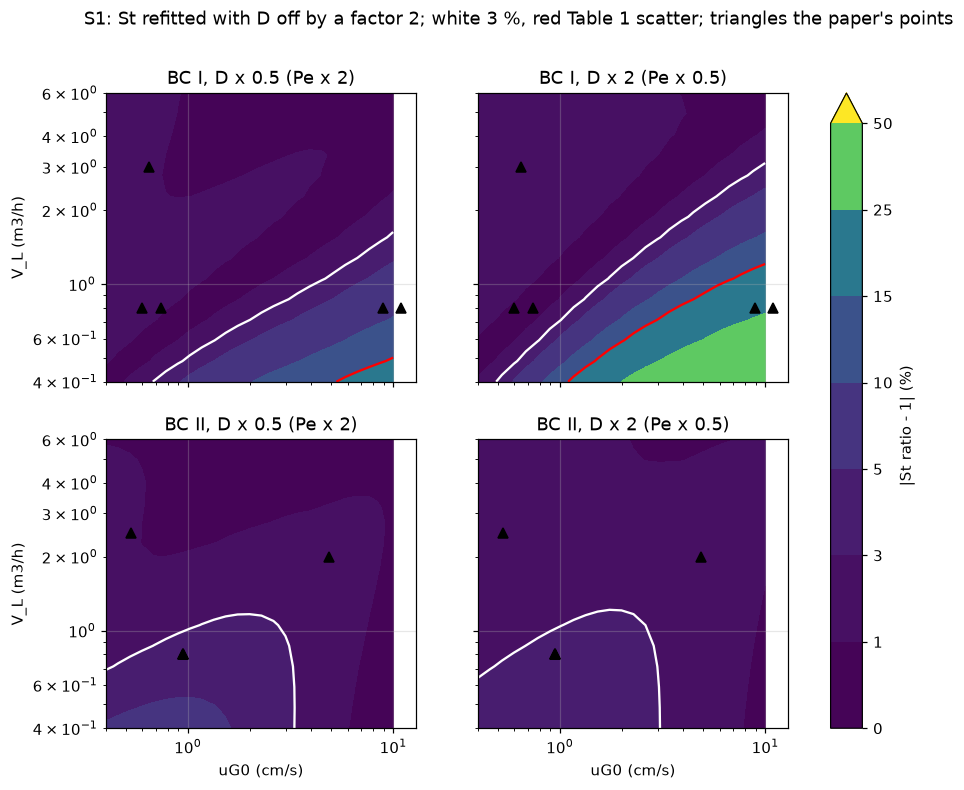

In [10]:
# The S1 map: |St ratio - 1| over uG and V_L for each column and direction (design D2).
UG_MAP = np.geomspace(0.4, 10.0, 25)
VL_MAP = np.geomspace(0.4, 6.0, 15)
MAP = {}
for col, pid in (("BC I", "F10-BCI-H2O-0.8"), ("BC II", "F10-BCII-H2O-2.5")):
    for f in (2.0, 0.5):
        MAP[(col, f)] = np.array([[abs(s1_case(point(pid, VL=VL, uG=u, eps=eps_line(col, u)), f)[0] - 1)
                                   for u in UG_MAP] for VL in VL_MAP])
fig, axs = plt.subplots(2, 2, figsize=(10, 7.5), sharex=True, sharey=True)
for i, col in enumerate(DIMS):
    for j, f in enumerate((2.0, 0.5)):
        ax = axs[i, j]
        cs = ax.contourf(UG_MAP, VL_MAP, 100 * MAP[(col, f)], levels=[0, 1, 3, 5, 10, 15, 25, 50],
                         cmap="viridis", extend="max")
        ax.contour(UG_MAP, VL_MAP, MAP[(col, f)], levels=[0.03, SCATTER[col]],
                   colors=["w", "r"], linewidths=[1.5, 1.5])
        for p in R1_PTS:
            if p["column"] == col:
                ax.plot(p["uG"], p["VL"], "k^", ms=6)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"{col}, D x {1 / f:g} (Pe x {f:g})")
        if i == 1:
            ax.set_xlabel("uG0 (cm/s)")
        if j == 0:
            ax.set_ylabel("V_L (m3/h)")
fig.colorbar(cs, ax=axs, label="|St ratio - 1| (%)")
fig.suptitle("S1: St refitted with D off by a factor 2; white 3 %, red Table 1 scatter; "
             "triangles the paper's points")
plt.show()

### R3. S2: plug flow (NTU) and stirred tank

BC II, desorption into nitrogen, $c^* = 0$: the closed-vessel outlet $c(1)/c_0$ is then
free of $H$ and of the feed. The two-point NTU evaluation infers
$\mathrm{St}_{\mathrm{NTU}} = \ln(c_0/c(1))$; its ratio to the dispersion model's St is
what S2 bounds. The stirred-tank two-point evaluation infers
$\mathrm{St}_{\mathrm{CSTR}} = (c_0 - c(1))/c(1)$. Fig. 11 draws the BC II correlation and
a dashed NTU line; their ratio at six gas velocities is read from the figure, and the
liquid flow at which the dispersion model gives that ratio is the liquid flow the NTU
runs imply. The paper does not print that flow.

In [11]:
F11_RATIO = (F11.kLa_NTU_line / F11.kLa_BCII_line).to_numpy()
UG_F11 = F11.uG0_cm_s.to_numpy()


PRINTED_MOL = [p for p in OPS.index if p.startswith("F9-BCII-mol")]
PRINTED_H2O = "F10-BCII-H2O-2.5"


def s2_ratios(VL, uG, K=K0, swap_table=False, drop_epsL=False, c0plus=False, inlet_sign=1.0,
              pid=None):
    """NTU and stirred-tank two-point St over the dispersion model's St (BC II, c* = 0).

    With ``pid`` the point is one of the paper's printed operating points (its own V_L, uG,
    holdup and Table 1 row); otherwise the tap-water line of Fig. 10 at ``VL`` and ``uG``.
    """
    if pid is None:
        pt = point(PRINTED_H2O, K, VL=VL, uG=uG, eps=eps_line("BC II", uG),
                   swap_table=swap_table, drop_epsL=drop_epsL)
    else:
        pt = point(pid, K, swap_table=swap_table, drop_epsL=drop_epsL)
    out, inlet = adm_profile([1.0, 0.0], pt["Pe"], pt["St"], 0, 0, 0, 1.0, inlet_sign)
    feed = inlet if c0plus else 1.0      # c0plus: the jumped inlet face read as the feed
    with np.errstate(invalid="ignore"):  # a broken inlet can make c(1) negative: nan, not a ratio
        return (st_two_point_ntu(out, feed) / pt["St"],
                st_two_point_cstr(out, feed, 0.0, 0.0) / pt["St"])


def study_r3(K=K0, swap_table=False, drop_epsL=False, c0plus=False, inlet_sign=1.0,
             f11_invert=False, show=False):
    """R3: NTU ratio at V_L 0.8 and 2.5, roots for ratio 0.8 and for Fig. 11's ratios.

    ``f11_invert`` reads Fig. 11's ratio the wrong way round (BC II line over NTU line).
    """
    kw = dict(K=K, swap_table=swap_table, drop_epsL=drop_epsL, c0plus=c0plus,
              inlet_sign=inlet_sign)
    f11 = 1 / F11_RATIO if f11_invert else F11_RATIO
    out = {"t1_scatter_BCII_water": (SCATTER[OTHER["BC II"] if swap_table else "BC II"], dict(
               kind="value", rtol=1e-9, note="Table 1 relative mean deviation, BC II water")),
           "s2_fig11_ratio_min": (f11.min(), dict(kind="value", rtol=1e-9)),
           "s2_fig11_ratio_max": (f11.max(), dict(kind="value", rtol=1e-9))}
    mol = [s2_ratios(None, None, **kw, pid=p)[0] for p in PRINTED_MOL]
    out["s2_ntu_ratio_printed_mol_min"] = (min(mol), dict(
        kind="value", rtol=1e-9, note="Fig. 9 BC II molasses points, printed V_L and uG"))
    out["s2_ntu_ratio_printed_mol_max"] = (max(mol), dict(kind="value", rtol=1e-9))
    out["s2_ntu_ratio_printed_H2O"] = (s2_ratios(None, None, **kw, pid=PRINTED_H2O)[0], dict(
        kind="value", rtol=1e-9, note="BC II water point of Fig. 10, printed V_L and uG"))
    ntu = {VL: np.array([s2_ratios(VL, u, **kw)[0] for u in UG_F11]) for VL in (0.8, 2.5)}
    cstr = np.array([s2_ratios(VL, u, **kw)[1] for VL in (0.8, 2.5) for u in UG_F11])
    for VL in (0.8, 2.5):
        t = str(VL).replace(".", "p")
        out[f"s2_ntu_ratio_VL{t}_min"] = (ntu[VL].min(), dict(kind="value", rtol=1e-9))
        out[f"s2_ntu_ratio_VL{t}_max"] = (ntu[VL].max(), dict(kind="value", rtol=1e-9))
    out["s2_count_ntu_within_20pct"] = (int(np.sum(np.r_[ntu[0.8], ntu[2.5]] > 0.8)), dict(
        kind="count", values=np.r_[ntu[0.8], ntu[2.5]], threshold=0.8, min_margin=1e-3,
        note="NTU St at least 0.8 times the dispersion St, at the six Fig. 11 uG and V_L 0.8, 2.5"))
    out["s2_count_cstr_too_high"] = (int(np.sum(cstr > 1)), dict(
        kind="count", values=cstr, threshold=1.0, min_margin=1e-3,
        note="stirred-tank St above the dispersion St (p. 2180: too high)"))
    out["s2_cstr_ratio_min"] = (cstr.min(), dict(kind="value", rtol=1e-9))
    roots08, implied = [], []
    for u, rf in zip(UG_F11, f11):
        for target, store in ((0.8, roots08), (rf, implied)):
            res = find_roots(lambda VL: s2_ratios(VL, u, **kw)[0] - target, 0.4, 6.0,
                             n_scan=32, log=True, xtol=1e-12)
            store.append(res["roots"][0] if len(res["roots"]) == 1 else np.nan)
    for u, v in zip(UG_F11, implied):
        out[f"s2_implied_VL_uG{str(u).replace('.', 'p')}"] = (v, dict(kind="value", rtol=1e-6,
                                                                       unit="m3/h"))
    for u, v in zip(UG_F11, roots08):
        out[f"s2_VL_ratio0p8_uG{str(u).replace('.', 'p')}"] = (v, dict(kind="value", rtol=1e-6,
                                                                        unit="m3/h"))
    b0, b1 = table1(OTHER["BC II"] if swap_table else "BC II", "water")
    f11_dev = F11.kLa_BCII_line.to_numpy() / kla_eq8(UG_F11, b0, b1) - 1
    out["v4_fig11_line_max_dev"] = (np.abs(f11_dev).max(), dict(
        kind="value", rtol=1e-9, note="Fig. 11 BC II line read against Table 1, largest |rel dev|"))
    if show:
        print(f"{'uG0':>5s} {'Fig.11 ratio':>12s} {'NTU V_L 0.8':>11s} {'NTU V_L 2.5':>11s} "
              f"{'implied V_L':>11s} {'V_L at 0.8':>10s} {'line/Table1-1':>13s}")
        for i, u in enumerate(UG_F11):
            print(f"{u:5.2f} {F11_RATIO[i]:12.3f} {ntu[0.8][i]:11.3f} {ntu[2.5][i]:11.3f} "
                  f"{implied[i]:11.3f} {roots08[i]:10.3f} {f11_dev[i]:13.4f}")
    return out, ntu, implied


R3, R3_NTU, R3_IMPLIED = study_r3(show=True)
print(f"\nNTU St over dispersion St: {R3['s2_ntu_ratio_VL0p8_min'][0]:.3f} to "
      f"{R3['s2_ntu_ratio_VL0p8_max'][0]:.3f} at V_L 0.8 m3/h, {R3['s2_ntu_ratio_VL2p5_min'][0]:.3f} "
      f"to {R3['s2_ntu_ratio_VL2p5_max'][0]:.3f} at 2.5; within S2's 20 % in "
      f"{R3['s2_count_ntu_within_20pct'][0]} of 12 cases.")
print(f"Stirred tank above the dispersion St in {R3['s2_count_cstr_too_high'][0]} of 12 cases "
      f"(smallest ratio {R3['s2_cstr_ratio_min'][0]:.3f}): p. 2180's sign holds.")
print(f"Fig. 11's NTU line lies at {R3['s2_fig11_ratio_min'][0]:.3f} to "
      f"{R3['s2_fig11_ratio_max'][0]:.3f} of its BC II line; the ratio reaches 0.8 at V_L "
      f"{R3['s2_VL_ratio0p8_uG0p6'][0]:.2f} (uG 0.6) to {R3['s2_VL_ratio0p8_uG1p5'][0]:.2f} "
      f"(uG 1.5) m3/h, and the NTU St over the dispersion St at the printed BC II points is "
      f"{R3['s2_ntu_ratio_printed_mol_min'][0]:.3f} to {R3['s2_ntu_ratio_printed_mol_max'][0]:.3f} "
      f"(molasses, Fig. 9) and {R3['s2_ntu_ratio_printed_H2O'][0]:.3f} (water, Fig. 10).")
print(f"Fig. 11's BC II line against Table 1: largest deviation "
      f"{100 * R3['v4_fig11_line_max_dev'][0]:.1f} %, the reading error of R3's ratios.")

  uG0 Fig.11 ratio NTU V_L 0.8 NTU V_L 2.5 implied V_L V_L at 0.8 line/Table1-1
 0.60        0.840       0.622       0.908       1.730      1.462        0.0166
 0.70        0.846       0.595       0.895       1.930      1.591        0.0171
 0.80        0.848       0.571       0.883       2.099      1.710        0.0157
 1.00        0.854       0.532       0.860       2.425      1.928        0.0175
 1.20        0.864       0.501       0.839       2.814      2.123        0.0173
 1.50        0.878       0.464       0.812       3.384      2.384        0.0156

NTU St over dispersion St: 0.464 to 0.622 at V_L 0.8 m3/h, 0.812 to 0.908 at 2.5; within S2's 20 % in 6 of 12 cases.
Stirred tank above the dispersion St in 12 of 12 cases (smallest ratio 2.634): p. 2180's sign holds.
Fig. 11's NTU line lies at 0.840 to 0.878 of its BC II line; the ratio reaches 0.8 at V_L 1.46 (uG 0.6) to 2.38 (uG 1.5) m3/h, and the NTU St over the dispersion St at the printed BC II points is 0.611 to 0.686 (molasses,

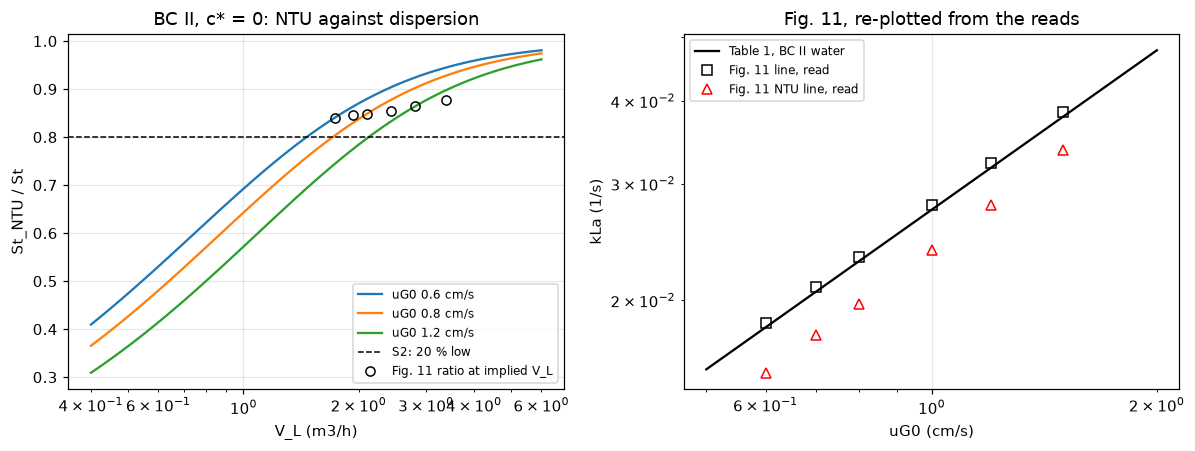

In [12]:
VL_PLOT = np.geomspace(0.4, 6.0, 60)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for u in UG_F11[::2]:
    axs[0].plot(VL_PLOT, [s2_ratios(v, u)[0] for v in VL_PLOT], label=f"uG0 {u:g} cm/s")
axs[0].axhline(0.8, color="k", ls="--", lw=1, label="S2: 20 % low")
axs[0].plot(R3_IMPLIED, F11_RATIO, "ko", mfc="none", label="Fig. 11 ratio at implied V_L")
axs[0].set_xscale("log"); axs[0].set_xlabel("V_L (m3/h)"); axs[0].set_ylabel("St_NTU / St")
axs[0].set_title("BC II, c* = 0: NTU against dispersion"); axs[0].legend(fontsize=8)
ug = np.geomspace(0.5, 2.0, 50)
axs[1].loglog(ug, kla_eq8(ug, *table1("BC II", "water")), "k-", label="Table 1, BC II water")
axs[1].loglog(UG_F11, F11.kLa_BCII_line, "ks", mfc="none", label="Fig. 11 line, read")
axs[1].loglog(UG_F11, F11.kLa_NTU_line, "r^", mfc="none", label="Fig. 11 NTU line, read")
axs[1].set_xlabel("uG0 (cm/s)"); axs[1].set_ylabel("kLa (1/s)"); axs[1].legend(fontsize=8)
axs[1].set_title("Fig. 11, re-plotted from the reads")
plt.tight_layout(); plt.show()

### R4. S3: the gas phase, with the coupled model

The coupled model at the four tap-water points (Fig. 9 BC I water and the three Fig. 10
water profiles), solved with `CoupledColumn` on $n$ = 640, 1280 and 2560 and
extrapolated. Its profile at design D2 is taken as the truth, and St is fitted to it
with the paper's two evaluation models: constant $y$ (eq. 6, $y = y_0$) and eq. 7 with
$\Delta y_t$ from the overall balance at the measured outlet. Salt and molasses points
are left out: their concentrations are relative (p. 2180), so the gas capacity is
unknown.

In [13]:
VL_SCAN = np.geomspace(0.4, 6.0, 13)
R4_IDS = ["F9-BCI-H2O", "F10-BCI-H2O-0.8", "F10-BCI-H2O-3.0", "F10-BCII-H2O-2.5"]
R4_TAG = {"F9-BCI-H2O": "F9BCI", "F10-BCI-H2O-0.8": "F10BCI0p8",
          "F10-BCI-H2O-3.0": "F10BCI3p0", "F10-BCII-H2O-2.5": "F10BCII"}


def r4_point(pid, K=K0, swap_table=False, drop_epsL=False, VL=None, inlet_sign=1.0,
             gas_outlet="outflow", outlet_read="face", bprime_sign=-1.0, b3_prefactor="St",
             balance="inert", two_term=True, dy_sign=1.0, gas_p="entry"):
    """Coupled truth at one point and the two fits over it."""
    pt = point(pid, K, VL=VL, swap_table=swap_table, drop_epsL=drop_epsL, gas_p=gas_p)
    q = unpack(coupled_extrapolated(pt, two_term, inlet_sign=inlet_sign, gas_outlet=gas_outlet,
                                    outlet_read=outlet_read, bprime_sign=bprime_sign), pt)
    r_cy, r_e7, dym = fit_cases(pt, q["data"], inlet_sign, bprime_sign, b3_prefactor, balance,
                                dy_sign=dy_sign)
    return dict(pt=pt, q=q, r_cy=r_cy, r_e7=r_e7, dym=dym)


def print_r4(res):
    """The R4 table."""
    print(f"{'point':18s} {'Pe':>6s} {'St':>6s} {'Lambda':>7s} {'dy_t':>8s} {'y(.5)-line':>10s} "
          f"{'const-y':>8s} {'eq. 7':>7s}")
    for pid, r in res.items():
        p = r["pt"]
        print(f"{pid:18s} {p['Pe']:6.2f} {p['St']:6.2f} {p['Lam']:7.4f} {r['q']['dyt']:8.4f} "
              f"{r['q']['y_half_dev']:10.5f} {r['r_cy']:8.4f} {r['r_e7']:7.4f}")


def study_r4(K=K0, swap_table=False, drop_epsL=False, inlet_sign=1.0, gas_outlet="outflow",
             outlet_read="face", bprime_sign=-1.0, b3_prefactor="St", balance="inert",
             two_term=True, dy_sign=1.0, gas_p="entry", root=True, sens=True, show=False):
    """R4: Delta y_t, the bend of y(x), and the constant-y and eq. 7 fits over the coupled truth."""
    kw = dict(K=K, swap_table=swap_table, drop_epsL=drop_epsL, inlet_sign=inlet_sign,
              gas_outlet=gas_outlet, outlet_read=outlet_read, bprime_sign=bprime_sign,
              b3_prefactor=b3_prefactor, balance=balance, two_term=two_term, dy_sign=dy_sign,
              gas_p=gas_p)
    res = {pid: r4_point(pid, **kw) for pid in R4_IDS}
    out = {}
    for pid, r in res.items():
        t = R4_TAG[pid]
        out[f"s3_dyt_{t}"] = (r["q"]["dyt"], dict(kind="value", rtol=1e-5))
        out[f"s3_y_half_dev_{t}"] = (r["q"]["y_half_dev"], dict(
            kind="value", rtol=1e-3, note="y(0.5) minus eq. 7's straight line"))
        out[f"s3_fit_cy_{t}"] = (r["r_cy"], dict(kind="value", rtol=1e-5,
                                                 note="constant-y St over the coupled St"))
        out[f"s3_fit_e7_{t}"] = (r["r_e7"], dict(kind="value", rtol=1e-5,
                                                 note="eq. 7 St over the coupled St"))
    dyt = np.abs([r["q"]["dyt"] for r in res.values()])
    out["s3_count_dyt_within_0p04"] = (int(np.sum(dyt < 0.04)), dict(
        kind="count", values=dyt, threshold=0.04, above=False, min_margin=1e-3))
    gain = np.array([r["r_e7"] / r["r_cy"] - 1 for r in res.values()])
    out["s3_eq7_gain_max"] = (gain.max(), dict(kind="value", rtol=1e-4,
                                               note="eq. 7 St over constant-y St, minus 1"))
    bias_cy = np.array([1 - r["r_cy"] for r in res.values()])
    bias_e7 = np.array([1 - r["r_e7"] for r in res.values()])
    scat = np.array([SCATTER[r["pt"]["column"]] for r in res.values()])
    out["s3_count_cy_beyond_scatter"] = (int(np.sum(np.abs(bias_cy) > scat)), dict(
        kind="count", values=np.abs(bias_cy) / scat, threshold=1.0, min_margin=1e-3))
    out["s3_count_e7_beyond_scatter"] = (int(np.sum(np.abs(bias_e7) > scat)), dict(
        kind="count", values=np.abs(bias_e7) / scat, threshold=1.0, min_margin=1e-3))
    if root:
        pid, col = "F10-BCII-H2O-2.5", "BC II"

        def g(VL):
            return (1 - r4_point(pid, VL=VL, **kw)["r_cy"]) - SCATTER[col]
        rts = find_roots(g, 0.4, 6.0, n_scan=13, log=True, xtol=1e-8)["roots"]
        bias = np.array([g(v) + SCATTER[col] for v in VL_SCAN])
        out["s3_BCII_cy_bias_scatter_crossings"] = (len(rts), dict(
            kind="exact", note="roots of (constant-y bias - 14.6 %) over V_L 0.4 to 6, uG 0.53"))
        out["s3_BCII_scan_cy_beyond_scatter"] = (int(np.sum(bias > SCATTER[col])), dict(
            kind="count", values=bias / SCATTER[col], threshold=1.0, min_margin=1e-3,
            note=f"of {VL_SCAN.size} V_L from 0.4 to 6 m3/h, BC II water, uG 0.53"))
        out["s3_BCII_cy_bias_VL0p4"] = (bias[0], dict(kind="value", rtol=1e-4))
        out["s3_BCII_cy_bias_VL6"] = (bias[-1], dict(kind="value", rtol=1e-4))
        kw95 = dict(kw, K=dict(K, csat=K["csat"] * 0.95))
        bias95 = np.array([1 - r4_point(pid, VL=v, **kw95)["r_cy"] for v in VL_SCAN])
        out["s3_BCII_cy_bias_VL6_csat0p95"] = (bias95[-1], dict(
            kind="value", rtol=1e-4, note="as s3_BCII_cy_bias_VL6 with c*_sat 5 % lower"))
        out["s3_BCII_scan_cy_beyond_scatter_csat0p95"] = (int(np.sum(bias95 > SCATTER[col])), dict(
            kind="count", values=bias95 / SCATTER[col], threshold=1.0, min_margin=1e-3,
            note=f"of {VL_SCAN.size} V_L from 0.4 to 6 m3/h, c*_sat 5 % lower"))
    if sens:
        ch_csat, ch_naive = [], []
        for fac in (1.05, 0.95):
            Ks = dict(K, csat=K["csat"] * fac)
            for pid in R4_IDS:
                ch_csat.append(abs(r4_point(pid, **dict(kw, K=Ks))["r_cy"] - res[pid]["r_cy"]))
        for pid in R4_IDS:
            alt = "naive" if balance == "inert" else "inert"
            ch_naive.append(abs(fit_cases(res[pid]["pt"], res[pid]["q"]["data"], inlet_sign,
                                          bprime_sign, b3_prefactor, alt)[1] - res[pid]["r_e7"]))
        top = {pid: r4_point(pid, **dict(kw, gas_p="top")) for pid in R4_IDS}
        out["s3_sens_ptop_cy_F10BCII"] = (top["F10-BCII-H2O-2.5"]["r_cy"], dict(
            kind="value", rtol=1e-4, note="constant-y ratio, BC II water, n_G0 at p_t"))
        out["s3_sens_ptop_gain_max"] = (max(r["r_e7"] / r["r_cy"] - 1 for r in top.values()), dict(
            kind="value", rtol=1e-4, note="largest eq. 7 gain over the four points, n_G0 at p_t"))
        out["s3_sens_csat_max"] = (max(ch_csat), dict(
            kind="value", rtol=1e-3, note="largest change of the constant-y ratio, c*_sat +-5 %"))
        out["s3_sens_naive_balance_max"] = (max(ch_naive), dict(
            kind="value", rtol=1e-3, note="largest change of the eq. 7 ratio, naive balance"))
    if show:
        print_r4(res)
    return out, res


R4, R4_RES = study_r4(show=True)
print(f"\n|Delta y_t| below S3's 0.04 at {R4['s3_count_dyt_within_0p04'][0]} of 4 points. Eq. 7 "
      f"raises St over constant y by at most {100 * R4['s3_eq7_gain_max'][0]:.1f} % at the four "
      "points.")
print(f"Constant-y bias beyond the Table 1 scatter at {R4['s3_count_cy_beyond_scatter'][0]} of 4 "
      f"points; eq. 7 bias beyond it at {R4['s3_count_e7_beyond_scatter'][0]}.")
print(f"BC II, uG 0.53 cm/s: the constant-y bias crosses the 14.6 % scatter "
      f"{R4['s3_BCII_cy_bias_scatter_crossings'][0]} times on V_L 0.4 to 6 m3/h (find_roots) and "
      f"lies above it at {R4['s3_BCII_scan_cy_beyond_scatter'][0]} of {VL_SCAN.size} scan points; "
      f"{100 * R4['s3_BCII_cy_bias_VL0p4'][0]:.1f} % at V_L 0.4, "
      f"{100 * R4['s3_BCII_cy_bias_VL6'][0]:.1f} % at 6.")
print(f"The V_L scan: the constant-y bias at 6 m3/h is "
      f"{100 * R4['s3_BCII_cy_bias_VL6'][0]:.2f} % and {100 * R4['s3_BCII_cy_bias_VL6_csat0p95'][0]:.2f} % "
      f"with c*_sat 5 % lower; it lies above the {100 * SCATTER['BC II']:.1f} % scatter at "
      f"{R4['s3_BCII_scan_cy_beyond_scatter'][0]} of {VL_SCAN.size} scan points, "
      f"{R4['s3_BCII_scan_cy_beyond_scatter_csat0p95'][0]} with c*_sat 5 % lower.")
print(f"n_G0 at the top pressure p_t instead of the entry pressure: BC II water constant-y ratio "
      f"{R4['s3_sens_ptop_cy_F10BCII'][0]:.3f}, eq. 7 gain at most "
      f"{100 * R4['s3_sens_ptop_gain_max'][0]:.1f} %.")
print(f"H unknown: c*_sat +-5 % moves the constant-y ratio by at most "
      f"{R4['s3_sens_csat_max'][0]:.4f}; the naive balance moves the eq. 7 ratio by at most "
      f"{R4['s3_sens_naive_balance_max'][0]:.4f}.")

point                  Pe     St  Lambda     dy_t y(.5)-line  const-y   eq. 7
F9-BCI-H2O           1.71  72.92  0.0014  -0.0002   -0.00025   0.9865  0.9844
F10-BCI-H2O-0.8      3.22   6.74  0.0198  -0.0035   -0.00221   0.9381  0.9623
F10-BCI-H2O-3.0     12.52   1.60  0.0845  -0.0125   -0.00389   0.9313  0.9730
F10-BCII-H2O-2.5    17.86   1.85  0.1822   0.0150    0.00343   0.8314  0.9426

|Delta y_t| below S3's 0.04 at 4 of 4 points. Eq. 7 raises St over constant y by at most 13.4 % at the four points.
Constant-y bias beyond the Table 1 scatter at 1 of 4 points; eq. 7 bias beyond it at 0.
BC II, uG 0.53 cm/s: the constant-y bias crosses the 14.6 % scatter 0 times on V_L 0.4 to 6 m3/h (find_roots) and lies above it at 13 of 13 scan points; 16.9 % at V_L 0.4, 15.2 % at 6.
The V_L scan: the constant-y bias at 6 m3/h is 15.22 % and 14.54 % with c*_sat 5 % lower; it lies above the 14.6 % scatter at 13 of 13 scan points, 12 with c*_sat 5 % lower.
n_G0 at the top pressure p_t instead of the en

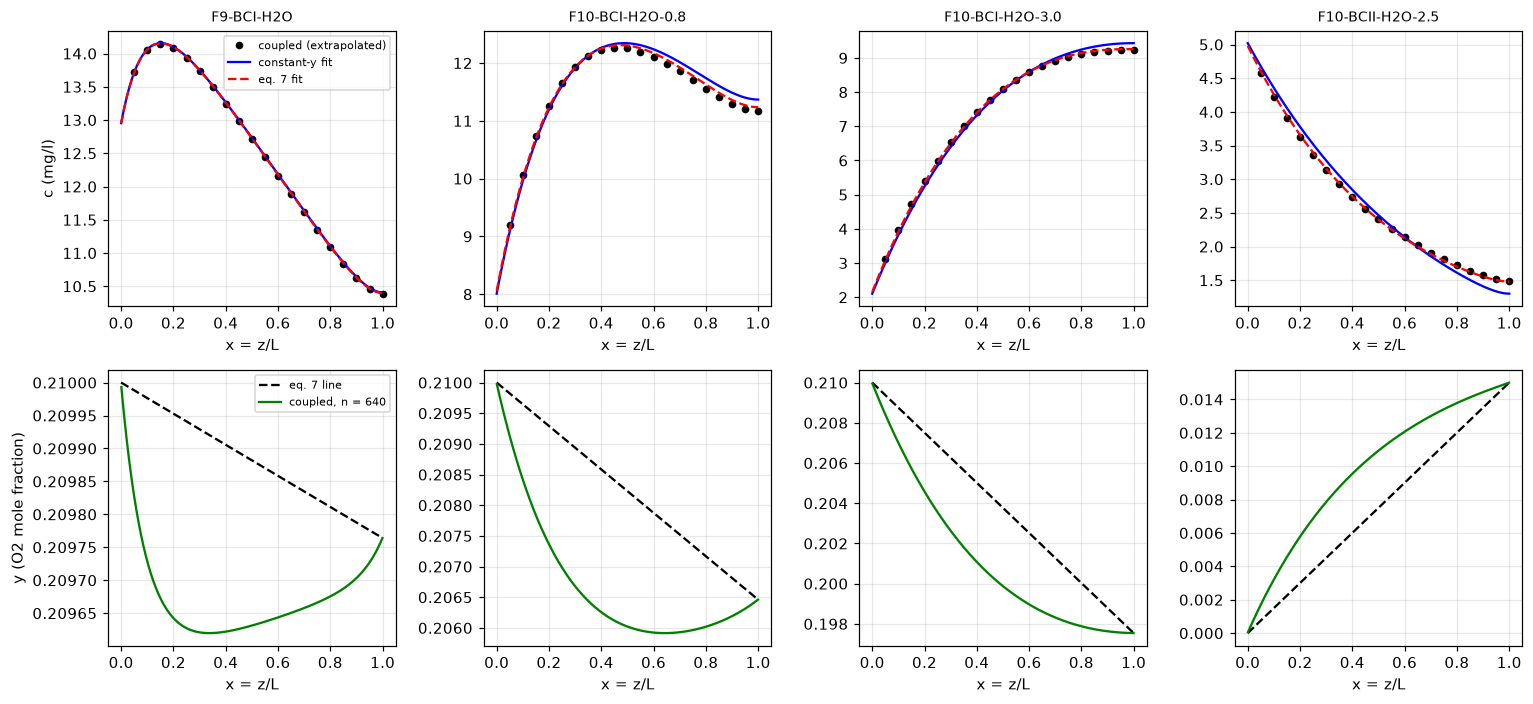

In [14]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6.5))
for j, (pid, r) in enumerate(R4_RES.items()):
    p, q = r["pt"], r["q"]
    xs = np.linspace(0, 1, 201)
    al, be, _ = cstar_coefficients(p["y0"], 0.0, K0["y_ref"], p["h"])
    a7, b7, g7 = cstar_coefficients(p["y0"], r["dym"], K0["y_ref"], p["h"])
    ax = axs[0, j]
    ax.plot(XK, q["data"] * p["c_ref"], "ko", ms=4, label="coupled (extrapolated)")
    ax.plot(xs, adm_profile(xs, p["Pe"], r["r_cy"] * p["St"], al, be, 0, p["theta0"]) * p["c_ref"],
            "b-", label="constant-y fit")
    ax.plot(xs, adm_profile(xs, p["Pe"], r["r_e7"] * p["St"], a7, b7, g7, p["theta0"]) * p["c_ref"],
            "r--", label="eq. 7 fit")
    ax.set_title(pid, fontsize=9); ax.set_xlabel("x = z/L")
    axs[1, j].plot([0, 1], [p["y0"], p["y0"] + q["dyt"]], "k--", label="eq. 7 line")
    m = CoupledColumn(p["Pe"], p["St"], p["Lam"], p["theta0"], p["psi0"], p["y0"], K0["y_ref"],
                      p["h"], n=640).solve()
    axs[1, j].plot(m.x_c, K0["y_ref"] * y_over_yref(m.c[:, 1], p["y0"], K0["y_ref"]), "g-",
                   label="coupled, n = 640")
    axs[1, j].set_xlabel("x = z/L")
axs[0, 0].set_ylabel("c (mg/l)"); axs[1, 0].set_ylabel("y (O2 mole fraction)")
axs[0, 0].legend(fontsize=7); axs[1, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Validation

### V1 to V3. The coupled solver: limits, refinement and an independent route

At T: the ladder $n = 80 \cdot 2^k$, $k = 0..5$, of $\theta(0)$, $\theta(1)$, $\psi(1)$ on
the faces and $\Delta y_t$; observed orders from successive differences
(`observed_orders`), theory 1 (upwind); the round-off companion is the change of the
finest values when the Jacobian is factorised under a second column ordering
(`permc_spec="MMD_ATA"`). The extrapolated values are compared with the `solve_bvp`
route, and two limits run through the same solver: $\Lambda = 0$ (the gas does not
change, against eqs. A6 to A11) and nitrogen with $\Lambda = 0$ ($c^* = 0$, against the
closed-vessel solution of A2.1).

In [15]:
NS_V = tuple(80 * 2 ** k for k in range(6))


def print_ladder(names, ns, vals, orders, finest, roundoff, ext, bvp, gap):
    """The V2 and V3 tables."""
    print(f"{'n':>6s} " + " ".join(f"{nm:>14s}" for nm in names))
    for n, v in zip(ns, vals):
        print(f"{n:6d} " + " ".join(f"{x:14.10f}" for x in v))
    print("orders (successive triples):")
    for o in orders:
        print("       " + " ".join(f"{x:14.3f}" for x in o))
    print("finest difference (here " + " ".join(f"{x:.2e}" for x in finest) + ")")
    print("round-off (MMD_ATA) (here " + " ".join(f"{x:.1e}" for x in roundoff) + ")")
    print("extrapolated: " + " ".join(f"{x:.10f}" for x in ext))
    print("solve_bvp:    " + " ".join(f"{x:.10f}" for x in bvp))
    print("relative gaps to solve_bvp (here " + " ".join(f"{x:.1e}" for x in gap) + ")")
    one = richardson(vals[-3:], False)
    print("with the first-order term only: " + " ".join(f"{x:.1e}" for x in
                                                        np.abs(one[:3] / bvp - 1)))


def study_v(inlet_sign=1.0, gas_outlet="outflow", outlet_read="face", two_term=True, K=K0,
            order_on="raw", companion_tol=1e-11, show=False):
    """V1 to V3 at T: orders, round-off companion, FV against solve_bvp, two limits, balance."""
    pt = point("F10-BCI-H2O-3.0", K, eps=EPS_T)
    ckw = dict(inlet_sign=inlet_sign, gas_outlet=gas_outlet, outlet_read=outlet_read)
    ns = NS_V

    def quad(n, **extra):
        u = unpack(coupled_values(pt, n, **ckw, **extra), pt)
        return np.array([u["th0f"], u["th1f"], u["psi1"], u["dyt"]])
    cache = {n: quad(n) for n in ns}
    if order_on == "extrapolated":     # a defect: the study fed with already extrapolated values
        cache = {n: richardson([quad(n // 4), quad(n // 2), cache[n]]) for n in ns}
    # one refinement study per quantity; the ladder is declared as doubling
    studies = [observed_orders(lambda n, i=i: cache[n][i], ns, ratio=2.0) for i in range(4)]
    vals = np.array([cache[n] for n in ns])
    orders = np.array([s["orders"] for s in studies]).T     # (triples, quantities)
    alt = quad(ns[-1], tol=companion_tol, lin_solver_kwargs={"permc_spec": "MMD_ATA"})
    roundoff = np.abs(alt - vals[-1])
    finest = np.abs(vals[-1] - vals[-2])
    ext = richardson(vals[-3:], two_term)
    sol = coupled_bvp(pt["Pe"], pt["St"], pt["Lam"], pt["theta0"], pt["psi0"], pt["y0"],
                      K0["y_ref"], pt["h"], tol=1e-10)
    bvp = np.array([sol.sol(0.0)[0], sol.sol(1.0)[0], sol.sol(1.0)[2]])
    gap = np.abs(ext[:3] / bvp - 1)
    # Lambda = 0: the gas keeps y0, so theta* is the linear c* of eqs. A6 to A11
    al, be, _ = cstar_coefficients(pt["y0"], 0.0, K0["y_ref"], pt["h"])
    l0 = richardson([coupled_values(pt, n, Lam=0.0, **ckw) for n in NS_R], two_term)
    gap_l0 = abs(l0[1] / adm_profile(1.0, pt["Pe"], pt["St"], al, be, 0, pt["theta0"]) - 1)
    # nitrogen and Lambda = 0: c* = 0, the closed vessel of A2.1
    n0 = richardson([coupled_values(dict(pt, theta0=1.0), n, Lam=0.0, y0=0.0, **ckw)
                     for n in NS_R], two_term)
    gap_cv = abs(n0[1] / danckwerts_outlet_ratio(pt["Pe"], pt["St"]) - 1)
    # the overall O2 balance with face values on the finest grid
    bal = abs((vals[-1][1] - pt["theta0"]) * pt["Lam"] / (pt["psi0"] - vals[-1][2]) - 1)
    names = ("c0", "c1", "psi1", "dyt")
    out = {}
    for i, nm in enumerate(names):
        out[f"v2_order_{nm}"] = (orders[-1][i], dict(
            kind="bound", min=0.8, max=1.2, basis="theory",
            note="first-order upwind; finest triple of n = 80 * 2^k, k = 0..5"))
        out[f"v2_roundoff_margin_{nm}"] = (finest[i] / max(roundoff[i], 1e-300), dict(
            kind="bound", min=100.0, basis="chosen",
            note="finest difference over the change under permc_spec MMD_ATA (rule 14)"))
    for i, nm in enumerate(names[:3]):
        out[f"v3_fv_vs_bvp_{nm}"] = (gap[i], dict(
            kind="bound", max=1e-7, basis="tolerance",
            note="extrapolated FV (orders 1 and 2 removed) against solve_bvp at tol 1e-10"))
    out["v1_lambda0_vs_A6_A11"] = (gap_l0, dict(kind="bound", max=1e-7, basis="tolerance",
                                                note="extrapolated FV outlet, Lambda = 0"))
    out["v1_cstar0_vs_closed_vessel"] = (gap_cv, dict(kind="bound", max=1e-7, basis="tolerance",
                                                      note="extrapolated FV outlet, c* = 0"))
    out["v3_o2_balance"] = (bal, dict(kind="bound", max=1e-9, basis="identity",
                                      note="theta(1) - theta0 = (psi0 - psi(1))/Lambda on faces, "
                                           "n = 2560; newton tol 1e-11"))
    if show:
        print_ladder(names, ns, vals, orders, finest, roundoff, ext, bvp, gap)
    return out


V = study_v(show=True)
print(f"Lambda = 0 against A6 to A11 (here {V['v1_lambda0_vs_A6_A11'][0]:.1e}); c* = 0 against "
      f"the closed vessel (here {V['v1_cstar0_vs_closed_vessel'][0]:.1e}); O2 balance on the "
      f"faces (here {V['v3_o2_balance'][0]:.1e})")

     n             c0             c1           psi1            dyt
    80   0.2304397466   0.9342832476   0.9262781912  -0.0124227722
   160   0.2262218025   0.9352843775   0.9261936910  -0.0124372354
   320   0.2239712814   0.9357852215   0.9261514173  -0.0124444712
   640   0.2228087333   0.9360356975   0.9261302759  -0.0124480900
  1280   0.2222178868   0.9361609471   0.9261197043  -0.0124498995
  2560   0.2219200383   0.9362235744   0.9261144182  -0.0124508043
orders (successive triples):
                0.906          0.999          0.999          0.999
                0.953          1.000          1.000          1.000
                0.976          1.000          1.000          1.000
                0.988          1.000          1.000          1.000
finest difference (here 2.98e-04 6.26e-05 5.29e-06 9.05e-07)
round-off (MMD_ATA) (here 9.1e-14 2.5e-13 4.0e-14 6.8e-15)
extrapolated: 0.2216205730 0.9362862036 0.9261091320 -0.0124517092
solve_bvp:    0.2216205605 0.9362862035 0.92610

### The misprints and the limits, measured at T

Each misprint's effect on the outlet at T, and the two limits of the closed form:
$\mathrm{Pe} \to \infty$ against plug flow and $\mathrm{Pe} \to 0$ against the stirred tank.
Each misprint quantity is computed with the printed form and the corrected one; a row of
the break table that puts the printed form everywhere makes the difference vanish.

In [16]:
def study_mp(inlet_sign=1.0, b3_prefactor="St", bprime_sign=-1.0, balance="inert", show=False):
    """Misprint effects and the Pe limits at T, closed forms (the coupled Delta y_t from Q_T)."""
    pt, th0 = PT_T, PT_T["theta0"]
    a, b, g = cstar_coefficients(K0["y_air"], 0.0, K0["y_ref"], pt["h"], bprime_sign)
    c1 = adm_profile(1.0, pt["Pe"], pt["St"], a, b, g, th0, inlet_sign)
    c1_a4 = adm_profile(1.0, pt["Pe"], pt["St"], a, b, g, th0, -1.0)
    aq_, bq_, gq_ = cstar_coefficients(K0["y_air"], -0.012, K0["y_ref"], pt["h"], bprime_sign)
    q1 = adm_profile(1.0, pt["Pe"], pt["St"], aq_, bq_, gq_, th0, inlet_sign, b3_prefactor)
    q1_a19 = adm_profile(1.0, pt["Pe"], pt["St"], aq_, bq_, gq_, th0, inlet_sign, "Pe")
    ap, bp, gp = cstar_coefficients(K0["y_air"], 0.0, K0["y_ref"], pt["h"], 1.0)
    c1_m3 = adm_profile(1.0, pt["Pe"], pt["St"], ap, bp, gp, th0, inlet_sign)
    printed = adm_printed_A6_A11(1.0, pt["Pe"], pt["St"], a, b, th0) / c1
    dy_alt = dy_from_outlet(Q_T["th1f"], th0, pt["Lam"], pt["psi0"], pt["y0"], K0["y_ref"], "naive")
    dy_used = dy_from_outlet(Q_T["th1f"], th0, pt["Lam"], pt["psi0"], pt["y0"], K0["y_ref"], balance)
    hi = adm_profile(1.0, 1e4, pt["St"], a, b, 0, th0, inlet_sign) / plug_profile(1.0, pt["St"], a, b, th0)
    lo = adm_profile(1.0, 1e-4, pt["St"], a, b, 0, th0, inlet_sign) / cstr_outlet(pt["St"], a, b, th0)
    out = {
        "m1_printed_A6_A11_over_corrected": (abs(printed - 1), dict(
            kind="bound", max=1e-12, basis="identity", structural=True,
            note="A6 to A11 as printed solve the Danckwerts inlet: one formula, two arrangements")),
        "m1_A4_printed_sign_c_out_shift": (c1_a4 / c1 - 1, dict(kind="value", rtol=1e-9)),
        "m2_A19_printed_c_out_shift": (q1_a19 / q1 - 1, dict(kind="value", rtol=1e-9)),
        "m3_bprime_printed_c_out_shift": (c1_m3 / c1 - 1, dict(kind="value", rtol=1e-9)),
        "m4_naive_over_exact_dyt": (dy_alt / dy_used, dict(kind="value", rtol=1e-5)),
        "lim_pe1e4_over_plug_minus_1": (hi - 1, dict(kind="value", rtol=1e-4)),
        "lim_pe1e-4_over_cstr_minus_1": (lo - 1, dict(kind="value", rtol=1e-3)),
    }
    if show:
        for k, (v, sp) in out.items():
            print(f"{k:36s} " + (f"(here {v:.1e})" if sp["kind"] == "bound" else f"{v: .6e}"))
    return out


MP = study_mp(show=True)

m1_printed_A6_A11_over_corrected     (here 4.4e-16)
m1_A4_printed_sign_c_out_shift       -9.816192e-02
m2_A19_printed_c_out_shift           -2.411907e-02
m3_bprime_printed_c_out_shift         6.541674e-01
m4_naive_over_exact_dyt               1.246181e+00
lim_pe1e4_over_plug_minus_1          -5.068803e-05
lim_pe1e-4_over_cstr_minus_1          6.220276e-06


### The finding

Each simplification set against the scatter of the paper's own correlation, at the
paper's operating points (numbers from the cells above):

In [17]:
print(f"S1, D off by a factor 2 (design D1, the real ports): |St ratio - 1| up to "
      f"{100 * R2['s1_D1_worst_dev'][0]:.1f} %; within 3 % in {R2['s1_D1_count_within_3pct'][0]} "
      f"of {R2['s1_D1_case_total'][0]} cases ({R2['s1_D1_count_within_3pct_epsp01'][0]} with eps_G "
      f"raised by {EPS_STEP}), within the Table 1 scatter in "
      f"{R2['s1_D1_count_within_scatter'][0]}.")
print(f"S2, plug flow (NTU), BC II: St ratio {R3['s2_ntu_ratio_VL0p8_min'][0]:.3f} to "
      f"{R3['s2_ntu_ratio_VL0p8_max'][0]:.3f} at V_L 0.8 m3/h ({R3['s2_count_ntu_within_20pct'][0]} "
      f"of 12 cases within 20 %), {R3['s2_ntu_ratio_VL2p5_min'][0]:.3f} to "
      f"{R3['s2_ntu_ratio_VL2p5_max'][0]:.3f} at 2.5; Fig. 11's own ratio "
      f"{R3['s2_fig11_ratio_min'][0]:.3f} to {R3['s2_fig11_ratio_max'][0]:.3f}. "
      f"Stirred tank: at least {R3['s2_cstr_ratio_min'][0]:.2f} times the dispersion St.")
print("S3, gas phase, against the coupled model: constant-y St ratios "
      + ", ".join(f"{R4[f's3_fit_cy_{t}'][0]:.3f}" for t in R4_TAG.values())
      + "; eq. 7 " + ", ".join(f"{R4[f's3_fit_e7_{t}'][0]:.3f}" for t in R4_TAG.values())
      + f"; beyond the scatter: constant y {R4['s3_count_cy_beyond_scatter'][0]} of 4, "
      f"eq. 7 {R4['s3_count_e7_beyond_scatter'][0]} of 4.")

S1, D off by a factor 2 (design D1, the real ports): |St ratio - 1| up to 15.3 %; within 3 % in 17 of 20 cases (16 with eps_G raised by 0.01), within the Table 1 scatter in 19.
S2, plug flow (NTU), BC II: St ratio 0.464 to 0.622 at V_L 0.8 m3/h (6 of 12 cases within 20 %), 0.812 to 0.908 at 2.5; Fig. 11's own ratio 0.840 to 0.878. Stirred tank: at least 2.63 times the dispersion St.
S3, gas phase, against the coupled model: constant-y St ratios 0.987, 0.938, 0.931, 0.831; eq. 7 0.984, 0.962, 0.973, 0.943; beyond the scatter: constant y 1 of 4, eq. 7 0 of 4.


**Reading the numbers.** S1 holds at the measuring ports in most of the cases (counts
printed above) and fails at the Fig. 9 BC I points, where St is large and the profile is
flat after the first tenth of the column, and once at the Fig. 10 BC I point at the lower
liquid flow with D halved. D is above 100 cm²/s at those points, so S1's threshold is not
what decides it: the port positions and St are. S2 holds for Fig. 11 as drawn, where the
NTU line lies inside 20 per cent of the BC II line, and is not a general bound: the
dispersion model puts the NTU evaluation more than 20 per cent low, and beyond the Table 1
scatter, at the liquid flow of Fig. 9, and no single liquid flow reproduces Fig. 11's
ratios. A stirred-tank evaluation is far off everywhere, as p. 2180 says. S3 holds: eq. 7
raises St by less than the paper's 20 per cent at the four points. Against the coupled
model the constant-$y$ evaluation is low by more than the scatter at the BC II water point
of Fig. 10, and at every liquid flow scanned there for the saturation value used (the
margin at the top of the scan is smaller than a 5 % change of $c^*_{\mathrm{sat}}$ moves
it); eq. 7 brings it back within. At the BC I absorption points the constant-$y$
evaluation stays within the scatter.

## What pymrm adds

The paper never solves the coupled liquid-gas model; it prescribes the gas composition
and says the coupled balance is nonlinear. pymrm solves it here as one Newton system,
two fields on finite-volume operators assembled once, the exchange Jacobian from
`NumJac` on the $(n, 2)$ layout, outlet values on the faces by
`compute_boundary_values`, a refinement study by `observed_orders` and every crossing
by `find_roots`. That solve is what turns S3 from a statement into a measured bias of
each evaluation model against a consistent truth. R1 to R3 are closed forms; pymrm
contributes only `find_roots` there.

## Reuse

- To evaluate $k_La$ from another column's liquid profile, use `adm_profile` with the
  column's Pe and the gas composition as a polynomial in $x$, and `fit_stanton`; the
  S1 map above shows where Pe matters.
- Where the gas composition change matters, solve `CoupledColumn` (or `coupled_bvp`)
  instead of prescribing $y$; set $\Lambda$ by `capacity_ratio`. Read outlet values
  with `compute_boundary_values`, never from the last cell; the gas outlet is
  `{"outflow": True}`.
- The upwind discretisation is first order with a strong second-order term at the
  inlet face: extrapolate with both terms, or use a finer grid.

**Related pages.** [`A2.1`](../A2.1-danckwerts-boundary-conditions/) (the Danckwerts
conditions), [`F1.1`](../F1.1-akita-yoshida-bubble-column/) ($k_La$ and holdup
correlations), [`F2.3`](../F2.3-slurry-bubble-column-ft/) (a bubble-column reactor
on pymrm).

**Cite the source, not this page:** Deckwer, W.-D., Burckhart, R. and Zoll, G.,
*Mixing and mass transfer in tall bubble columns*, Chemical Engineering Science **29**
2177-2188 (1974), [doi:10.1016/0009-2509(74)80025-4](https://doi.org/10.1016/0009-2509(74)80025-4).

### Claims and the defect-injection table

Every number above is registered as a claim. Each row of the table breaks one thing on
purpose through an argument of the studies above (a misprint restored, an input taken
the wrong way, a numerical shortcut), re-runs every study that argument enters, and
records whether each claim's own check catches the change.

In [18]:
BASE = {"R1": R1, "R2": R2, "R3": R3, "R4": R4, "V": V, "MP": MP}
for study in BASE.values():
    for name, (val, spec) in study.items():
        spec = dict(spec)
        kind = spec.pop("kind")
        if kind == "count":
            claims.count(name, spec.pop("values"), spec.pop("threshold"), **spec)
        elif kind == "exact":
            claims.exact(name, val, **spec)
        else:
            getattr(claims, kind)(name, val, **spec)

STUDY_FN = {"R1": lambda **k: study_r1(**k)[0], "R2": lambda **k: study_r2(**k)[0],
            "R3": lambda **k: study_r3(**k)[0], "R4": lambda **k: study_r4(**k)[0],
            "V": study_v, "MP": study_mp}
K_EXP = dict(K0, D_exp_uG=0.5)
K_MG = dict(K0, M=K0["M"] * 1e3)
K_RJ = dict(K0, R=8314.46)       # J/(kmol K) where cm3 atm/(mol K) belongs: Lambda x 101
K_CS = dict(K0, csat=K0["csat"] * 0.95)    # the unprinted saturation value 5 % low
K_DC = dict(K0, D_coef=K0["D_coef"] * 2)   # eq. 1 with its coefficient twice as large
ROWS = [
    ("A4 inlet sign as printed (M1)", {"R2": dict(inlet_sign=-1.0), "R3": dict(inlet_sign=-1.0),
                                        "V": dict(inlet_sign=-1.0), "MP": dict(inlet_sign=-1.0)}),
    ("A19 B3 prefactor as printed (M2)", {"R4": dict(b3_prefactor="Pe", root=False),
                                          "MP": dict(b3_prefactor="Pe")}),
    ("A13 b' with the printed sign (M3)", {"R2": dict(bprime_sign=1.0, roots=False),
                                           "R4": dict(bprime_sign=1.0, root=False, sens=False),
                                           "MP": dict(bprime_sign=1.0)}),
    ("naive gas balance for Delta y_t (M4)", {"R4": dict(balance="naive", root=False),
                                              "MP": dict(balance="naive")}),
    ("Lambda with mg for g in M_O2", {"R4": dict(K=K_MG), "V": dict(K=K_MG)}),
    ("R in J/(kmol K) for cm3 atm/(mol K)", {"R4": dict(K=K_RJ, root=False, sens=False)}),
    ("eq. 7 with Delta y_t of the wrong sign", {"R4": dict(dy_sign=-1.0, root=False, sens=False)}),
    ("eq. 1 uG exponent 0.5 for 0.3", {"R1": dict(K=K_EXP), "R2": dict(K=K_EXP),
                                       "R3": dict(K=K_EXP), "R4": dict(K=K_EXP, sens=False)}),
    ("Table 1 BC I and BC II rows swapped", {"R1": dict(swap_table=True),
                                             "R2": dict(swap_table=True),
                                             "R3": dict(swap_table=True),
                                             "R4": dict(swap_table=True, sens=False)}),
    ("(1 - eps_G) dropped in Pe", {"R1": dict(drop_epsL=True), "R2": dict(drop_epsL=True),
                                   "R3": dict(drop_epsL=True),
                                   "R4": dict(drop_epsL=True, sens=False)}),
    ("BC I and BC II dimensions swapped", {"R1": dict(swap_dims=True)}),
    ("two-point NTU with c(0+) for the feed", {"R3": dict(c0plus=True)}),
    ("gas outlet zero gradient (P6)", {"R4": dict(gas_outlet="zero_gradient", root=False,
                                                  sens=False),
                                       "V": dict(gas_outlet="zero_gradient")}),
    ("outlet read from the last cell (P8)", {"R4": dict(outlet_read="cell", root=False,
                                                        sens=False),
                                             "V": dict(outlet_read="cell")}),
    ("Richardson with the first-order term only", {"R4": dict(two_term=False, root=False,
                                                              sens=False),
                                                   "V": dict(two_term=False)}),
    ("orders measured on extrapolated values", {"V": dict(order_on="extrapolated")}),
    ("c*_sat 5 % low", {"R4": dict(K=K_CS, sens=False)}),
    ("eq. 1 coefficient twice as large", {"R1": dict(K=K_DC), "R2": dict(K=K_DC),
                                          "R3": dict(K=K_DC),
                                          "R4": dict(K=K_DC, root=False, sens=False)}),
    ("Fig. 11 ratio read upside down", {"R3": dict(f11_invert=True)}),
]
claims.define_rows([lab for lab, _ in ROWS])
TABLE, CRASHED, NO_NUMBER = [], [], []
for label, studies in ROWS:
    for sname, kw in studies.items():
        try:
            broken = STUDY_FN[sname](**kw)
        except Exception as exc:       # a crash is reported, never counted as a catch
            print(f"CRASH {label} / {sname}: {type(exc).__name__}: {exc}")
            CRASHED.append((label, sname))
            continue
        for name in BASE[sname]:
            if name not in broken:     # the row's study does not compute this claim
                continue
            val = broken[name][0]
            if not np.isfinite(val):   # no number came back: not a moved value
                NO_NUMBER.append((label, name))
                continue
            TABLE.append((label, name, claims[name], val, claims.breaks(label, name, val)))
print(f"{len(CRASHED)} study crash(es); {len(NO_NUMBER)} claim(s) came back without a number "
      "in a broken run and are not counted.")
print(f"{'row':44s} {'claim':38s} {'caught':>6s}")
for label, name, v0, v1, caught in TABLE:
    if caught:
        print(f"{label[:44]:44s} {name[:38]:38s} {'yes':>6s}")

0 study crash(es); 22 claim(s) came back without a number in a broken run and are not counted.
row                                          claim                                  caught
A4 inlet sign as printed (M1)                s1_D1_count_within_3pct                   yes
A4 inlet sign as printed (M1)                s1_D1_count_within_scatter                yes
A4 inlet sign as printed (M1)                s1_D1_worst_rms_rel                       yes
A4 inlet sign as printed (M1)                s1_D1_worst_change_rel                    yes
A4 inlet sign as printed (M1)                s1_D2_count_within_3pct                   yes
A4 inlet sign as printed (M1)                s1_D2_count_within_scatter                yes
A4 inlet sign as printed (M1)                s1_D2_worst_rms_rel                       yes
A4 inlet sign as printed (M1)                s1_D2_worst_change_rel                    yes
A4 inlet sign as printed (M1)                s1_D1_named_outside_count                

In [19]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F2.1:
  r1_Pe_min                               = 1.71             value  rtol 1e-09
  r1_Pe_max                               = 17.859           value  rtol 1e-09
  r1_St_min                               = 1.6017           value  rtol 1e-09
  r1_St_max                               = 72.919           value  rtol 1e-09
  r1_count_D_above_100                    = 9                exact  exact, margin 0.0111
  r1_D_lowest_cm2_s                       = 98.895           value  rtol 1e-09
  r1_uL0_fig5_halfunits                   = 0.71061          value  rtol 1e-06
  s1_D1_count_within_3pct                 = 17               exact  exact, margin 0.00409
  s1_D1_count_within_scatter              = 19               exact  exact, margin 0.0278
  s1_D1_worst_dev                         = 0.15314          value  rtol 1e-05
  s1_D1_worst_rms_rel                     = 0.035879         value  rtol 1e-05
  s1_D1_worst_change_rel                  = 0.098063         value  rtol 1e-09
  s1